## Import

### import

In [84]:
import os, io, gc, re, json, sys, warnings, h5py, numpy as np, pandas as pd, pywt
from pathlib import Path
from contextlib import redirect_stderr
from typing import Dict, List, Optional
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from scipy.stats import boxcox, kurtosis, norm, skew, entropy, pearsonr
import cairosvg
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from mpl_toolkits.axes_grid1 import ImageGrid
from PIL import Image
from matplotlib.patches import Patch
from collections import Counter
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator, rdMolDescriptors, rdPartialCharges, rdmolops, Draw
from rdkit.Chem.Draw import rdMolDraw2D, SimilarityMaps
from rdkit.Chem.EState.EState import EStateIndices
from sklearn.covariance import LedoitWolf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, RepeatedKFold, ShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import umap
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.feature_selection import VarianceThreshold
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, RationalQuadratic, WhiteKernel
from sklearn.linear_model import ElasticNet, HuberRegressor, Lasso, Ridge
import catboost as cb, lightgbm as lgb, optuna, xgboost as xgb

import numpy as np, io, cairosvg, matplotlib.pyplot as plt
from PIL import Image
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors as MD, rdPartialCharges, rdmolops, rdDepictor
from rdkit.Chem.EState import EStateIndices
from rdkit.Chem.Draw import rdMolDraw2D, SimilarityMaps


import numpy as np, matplotlib.pyplot as plt
from rdkit.Chem import rdMolDescriptors as rdMD, rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import display, SVG, HTML
try:
    import cairosvg; from io import BytesIO; from PIL import Image
    raster = lambda s: np.array(Image.open(BytesIO(cairosvg.svg2png(bytestring=s.encode()))))
except ImportError: raster = None



SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams.update({"figure.dpi":200,"font.family":"serif","font.size":12,"axes.labelsize":14,"axes.titlesize":13,"xtick.labelsize":11,"ytick.labelsize":11,"figure.titlesize":16})

In [2]:
def read_sheet(path, cols):
    return pd.read_excel(path, sheet_name=0, header=None, skiprows=1) \
             .iloc[:, :len(cols)].set_axis(cols, axis=1)

def parse_std(s):
    s = str(s).replace(',', '.').strip()
    m = re.search(r'([\d.]+)\s*±\s*([\d.]+)', s)
    if m: return float(m.group(1)), float(m.group(2))
    try: return float(s), float(s) * 0.07
    except: return np.nan, np.nan

def load_and_prepare(data_dir='data'):
    c6 = ['Round','ML','Rank','No.','ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm','Fa_max','Fa_ave','d','Q']
    c5 = ['No.','ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm','Fa_max','Fa_ave','d','Q','G','Tanδ','k']
    cc = ['ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm']

    df = pd.concat([
        read_sheet(f'{data_dir}/41586_2025_9269_MOESM5_ESM.xlsx', c5),
        read_sheet(f'{data_dir}/41586_2025_9269_MOESM6_ESM.xlsx', c6)
    ], ignore_index=True)[cc + ['Fa_max','Fa_ave']]

    for c in cc + ['Fa_max']:
        df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce')

    df = df.dropna(subset=cc)
    df = df[~df[cc].round(4).duplicated()].reset_index(drop=True)

    df[cc] = df[cc].div(df[cc].sum(axis=1), axis=0)

    parsed = df['Fa_ave'].apply(parse_std)
    df['Fa_mean'] = parsed.apply(lambda x: x[0])
    df['Fa_std']  = parsed.apply(lambda x: x[1])

    mask = df['Fa_mean'].isna() & df['Fa_max'].notna()
    df.loc[mask, 'Fa_mean'] = df.loc[mask, 'Fa_max']
    df.loc[mask, 'Fa_std']  = df.loc[mask, 'Fa_mean'] * 0.05

    df = df[df['Fa_mean'] > 0].copy()
    return df.reset_index(drop=True), cc

mon_cols = ['ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm']
df, comp_cols = load_and_prepare()

#import data 
adhesion = df['Fa_mean'].values  
fractions_base_line = df.iloc[:, 0:6].to_numpy()

df

,ΦHEA,ΦBA,ΦCBEA,ΦATAC,ΦPEA,ΦAAm,Fa_max,Fa_ave,Fa_mean,Fa_std
0,0.518703,0.199302,0.094768,0.187226,0.000000,0.0,22.36,19.89±1.76,19.89,1.76
1,0.421787,0.406214,0.171999,0.000000,0.000000,0.0,12.57,11.06±1.94,11.06,1.94
2,0.536864,0.108375,0.184067,0.170693,0.000000,0.0,10.93,10.13±0.79,10.13,0.79
3,0.216356,0.199474,0.088142,0.174303,0.321725,0.0,126.82,109.57±12.43,109.57,12.43
4,0.119821,0.410078,0.191813,0.187167,0.091121,0.0,109.27,94.89±10.59,94.89,10.59
...,...,...,...,...,...,...,...,...,...,...
342,0.000000,0.640000,0.000000,0.070000,0.290000,0.0,235.47,219.32±19.58,219.32,19.58
343,0.000000,0.600000,0.000000,0.070000,0.330000,0.0,225.39,198.48±21.60,198.48,21.60
344,0.000000,0.606000,0.000000,0.081000,0.313000,0.0,229.75,216.26±12.41,216.26,12.41
345,0.000000,0.666000,0.000000,0.081000,0.253000,0.0,232.07,215.24±17.31,215.24,17.31


In [3]:
np.save('./data/ML/npys/fractions_baseline_no_compressed.npy', fractions_base_line)

In [4]:
fractions_base_line

array([[0.5187031 , 0.19930215, 0.09476832, 0.18722643, 0.        ,
        0.        ],
       [0.42178707, 0.40621375, 0.17199918, 0.        , 0.        ,
        0.        ],
       [0.53686431, 0.10837528, 0.18406719, 0.17069322, 0.        ,
        0.        ],
       ...,
       [0.        , 0.606     , 0.        , 0.081     , 0.313     ,
        0.        ],
       [0.        , 0.666     , 0.        , 0.081     , 0.253     ,
        0.        ],
       [0.        , 0.484     , 0.        , 0.061     , 0.455     ,
        0.        ]], shape=(347, 6))

### Import Func..

#### eMFP 

In [5]:

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

from tqdm import tqdm
from itertools import combinations
import psutil
import time
import pickle

from random import shuffle

import rdkit 
from rdkit import Chem 
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem
from rdkit import DataStructs
from rdkit.DataStructs import ConvertToNumpyArray
from rdkit.Chem import MolFromSmiles
from rdkit import rdBase
rdBase.DisableLog('rdApp.error')
rdBase.DisableLog('rdApp.*')

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.datasets import make_regression
from sklearn.metrics import mean_squared_error, r2_score


def mol_from_smiles(smiles):
    try:
        return Chem.MolFromSmiles(smiles)
    except:
        return None

def canonical_smiles(smiles):
    try:
        return Chem.MolToSmiles(Chem.MolFromSmiles(smiles))
    except:
        return None


def custom_descriptors(mol, descriptor_list, missingVal):
    descriptor_dictionary = {}
    for name, function in Descriptors._descList:
        if name in descriptor_list:
            try:
                val = function(mol)
            except:
                import traceback
                traceback.print_exc()
                val = missingVal
            descriptor_dictionary[name] = val
    return descriptor_dictionary

def get_custom_descriptors(molecular, case, descriptor_list):
    '''
    Calculate all descriptors for a list of molecules and organize the results in a DataFrame.
    https://greglandrum.github.io/rdkit-blog/posts/2022-12-23-descriptor-tutorial.html

    Args:
        molecular (list): List of molecular representations (SMILES strings or RDKit molecule objects).
        case (str): Case identifier, either 'smiles' or 'mol_object'.
        descriptor_list (list): List of descriptors to calculate

    Returns:
        pd.DataFrame: A pandas DataFrame where each row represents a molecule and each column
                      represents a molecular descriptor.
    '''
    if case == 'smiles':
        mols = [Chem.MolFromSmiles(smile) for smile in molecular]
        allDescrs = [custom_descriptors(m, descriptor_list, 0) for m in tqdm(mols, desc = 'Mols')]
    elif case == 'mol_object':
        allDescrs = [custom_descriptors(m, descriptor_list, 0) for m in tqdm(molecular, desc = 'Mols')]
    df = pd.DataFrame(allDescrs)
    return df

def get_all_descriptors(molecular, case):
    '''
    Calculate all descriptors for a list of molecules and organize the results in a DataFrame.
    https://greglandrum.github.io/rdkit-blog/posts/2022-12-23-descriptor-tutorial.html

    Args:
        molecular (list): List of molecular representations (SMILES strings or RDKit molecule objects).
        case (str): Case identifier, either 'smiles' or 'mol_object'.

    Returns:
        pd.DataFrame: A pandas DataFrame where each row represents a molecule and each column
                      represents a molecular descriptor.
    '''
    if case == 'smiles':
        mols = [Chem.MolFromSmiles(smile) for smile in molecular]
        allDescrs = [getMolDescriptors(m, 0) for m in tqdm(mols)]
    elif case == 'mol_object':
        allDescrs = [getMolDescriptors(m, 0) for m in tqdm(molecular)]
    df = pd.DataFrame(allDescrs)
    return df

def getMolDescriptors(mol, missingVal=0):
    '''
    Calculate the full list of descriptors for a molecule.
    https://greglandrum.github.io/rdkit-blog/posts/2022-12-23-descriptor-tutorial.html

    Args:
        mol (Chem.Mol): RDKit molecule object for which descriptors are to be calculated.
        missingVal (Optional): Value to be assigned if a descriptor cannot be calculated.

    Returns:
        dict: A dictionary containing molecular descriptors. The keys are descriptor names,
              and the values are the corresponding calculated descriptor values.
    '''
    res = {}
    for nm, fn in Descriptors._descList:
        # Some descriptor functions may raise errors; catch and handle those here:
        try:
            val = fn(mol)
        except Exception:
            # Print the error message:
            import traceback
            traceback.print_exc()
            # Set the descriptor value to whatever missingVal is:
            val = missingVal
        res[nm] = val
    return res

def calculate_morgan_fingerprints(molecules, radius=2, nbits=2048):
    """
    Calculate Morgan fingerprints for a list of molecules in RDKit object format.

    Args:
        molecules (list): List of RDKit Mol objects.
        radius (int): Radius for Morgan fingerprint calculation.
        nbits (int): Length of the Morgan fingerprints.

    Returns:
        list: List of numpy arrays representing the Morgan fingerprints for each molecule.
    """
    fingerprints_list = []

    for mol in tqdm(molecules, desc = 'MFP'):
        # Calculate Morgan fingerprints for each molecule
        fingerprint = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nbits, useChirality = True, useFeatures = True)
        fingerprint_array =  np.array(fingerprint)
        
        # # Convert the fingerprint to a numpy array
        # fingerprint_array = np.zeros((1,), dtype=np.int8)
        # ConvertToNumpyArray(fingerprint, fingerprint_array)

        fingerprints_list.append(fingerprint_array)

    return np.array(fingerprints_list)

def single_mfp(mol, radius, nbits):
    info = {}

    fingerprint = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nbits, useChirality = True, useFeatures = True)
    x = ''
    for item in fingerprint:
        x += str(item) + '&'
    return x



def convert_fp_to_embV2(vector, size):
    """
    Converts a fingerprint vector into a embedded vector using a specified size.
    Fingerprint shape must be N, M*size, Where N is the number of Fingerprints of
    N molecules and M*size means that the length of the fingerprint must be an 
    integer multiple of size

    Args:
        vector (numpy.ndarray): Input fingerprint vector.
        size (int): Size used for reshaping the fingerprint vector.

    Returns:
        numpy.ndarray: Embedded vector obtained by reshaping and processing the input fingerprint vector.

    Raises:
        ValueError: If the size is not a positive integer.
    """
    if not isinstance(size, int) or size <= 0:
        raise ValueError("Size must be a positive integer. Try size = 16, or size = 32")
    
    if len(vector.shape) == 1:
        rows = 1 
        cols = vector.shape[0]
    else:
        rows, cols = vector.shape

    narrays = cols // size

    mask = 2**np.arange(size, dtype = np.float64 )
    mask = mask/np.sum(mask)
    bigMask = np.tile(mask, (narrays, 1))

    tensorMask = np.tile(bigMask, (rows, 1))
    tensorMask = tensorMask.reshape((rows* narrays, size))
    vector_reshape = vector.reshape((rows* narrays, size))
    
    mfp_masked = tensorMask * vector_reshape
    mfp_maskedDotted = np.sum(mfp_masked, axis=1)
    
    if len(vector.shape) == 1:
        return mfp_maskedDotted.reshape((rows,narrays))
    else:
        return mfp_maskedDotted.reshape((rows,narrays)).squeeze()


def normalize_dataframe(df):
    """
    Normalize the values in each column of a Pandas DataFrame to the range [0, 1].

    Args:
        df (pd.DataFrame): Input DataFrame with numerical values.

    Returns:
        pd.DataFrame: DataFrame with values normalized between 0 and 1.

    Example:
        >>> import pandas as pd
        >>> from sklearn.preprocessing import MinMaxScaler
        >>> df = pd.DataFrame({'column1': [1, 2, 3, 4, 5],
        ...                    'column2': [10, 20, 30, 40, 50],
        ...                    'column3': [100, 200, 300, 400, 500]})
        >>> normalized_df = normalize_dataframe(df)
    """
    # Initialize the MinMaxScaler
    scaler = MinMaxScaler()

    # Normalize all columns of the DataFrame
    df_normalized = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

    return df_normalized


def columns_without_nan_inf(dataframe):
    """
    Returns a list of columns that do not contain NaN or infinity values.

    Parameters:
        dataframe (DataFrame): Input DataFrame.

    Returns:
        list: List of column names without NaN or infinity values.
    """
    nan_columns = dataframe.columns[dataframe.isna().any()].tolist()
    inf_columns = dataframe.columns[dataframe.isin([float('inf'), -float('inf')]).any()].tolist()
    nan_or_inf_columns = list(set(nan_columns + inf_columns))
    columns_without_nan_inf = [col for col in dataframe.columns if col not in nan_or_inf_columns]

    return columns_without_nan_inf

def common_elements(list1, list2):
    """
    Returns a list containing only the elements common to both input lists.

    Parameters:
        list1 (list): First input list.
        list2 (list): Second input list.

    Returns:
        list: List containing elements common to both input lists.
    """
    return list(set(list1) & set(list2))

def remove_nan_inf(df):
    """
    Remove columns containing NaN or Inf values from the dataframe.

    Args:
    df (pd.DataFrame): Input pandas dataframe.

    Returns:
    pd.DataFrame: Dataframe with NaN and Inf values removed.
    """
    # Remove columns with NaN or Inf values
    df_cleaned = df.replace([np.inf, -np.inf], np.nan).dropna(axis=1)
    return df_cleaned


def remove_non_numeric(df):
    """
    Remove columns containing non-numeric values from the dataframe.

    Args:
    df (pd.DataFrame): Input pandas dataframe.

    Returns:
    pd.DataFrame: Dataframe with non-numeric columns removed.
    """
    # Remove columns with non-numeric values
    numeric_columns = df.select_dtypes(include=[np.number]).columns
    df_numeric = df[numeric_columns]
    return df_numeric


def remove_correlated_features(df, threshold=0.9):
    """
    Remove correlated features from the dataframe.

    Args:
    df (pd.DataFrame): Input pandas dataframe.
    threshold (float, optional): Threshold for correlation coefficient. Features
        with correlation coefficient higher than this value will be considered
        correlated. Defaults to 0.9.

    Returns:
    pd.DataFrame: Dataframe with correlated features removed.
    """
    # Calculate correlation matrix
    corr_matrix = df.corr().abs()

    # Create a mask to remove the upper triangle of the correlation matrix
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    # Find index of feature columns with correlation greater than threshold
    features_to_drop = [column for column in corr_matrix.columns if any(corr_matrix[column] > threshold)]

    # Drop highly correlated features
    df_filtered = df.drop(columns=features_to_drop)
    return df_filtered


def get_minimal_columns(dfFeatures, threshold=0.95):
    """
    Returns the minimal list of columns that describe all features by removing highly correlated columns.
    
    Args:
        dfFeatures (pd.DataFrame): DataFrame containing the features.
        threshold (float): Correlation threshold to consider two columns as highly correlated.
        
    Returns:
        list: List of column names that minimally describe all features.
    """
    # Calculate the correlation matrix
    corr_matrix = dfFeatures.corr().abs()
    
    # Create a boolean matrix where True indicates high correlation
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    # Find columns with correlation greater than the threshold
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    
    # Create a list of remaining columns, removing the highly correlated ones
    remaining_columns = [column for column in dfFeatures.columns if column not in to_drop]
    
    return remaining_columns


def identify_bit_collisions(mol, radius, nbits):
    # Generate the Morgan fingerprint with counts
    info = {}
    fingerprint = AllChem.GetMorganFingerprint(mol, radius, bitInfo=info, useChirality=True, useFeatures=True)
    
    # Initialize a bit count array
    bit_counts = np.zeros(nbits, dtype=int)
    
    for bit, paths in info.items():
        bit_counts[bit] = len(paths)
    
    # Identify bit collisions
    collisions = np.where(bit_counts > 1)[0]
    
    return collisions, bit_counts


#### 
Git: https://github.com/MMLabCodes/eMFP


## Data update

### Make FFP and 2D

In [6]:
monomers = {
    'HEA': 'C=CC(=O)OCCO',                            # 2-Hydroxyethyl acrylate
    'BA': 'C=CC(=O)OCCCC',                            # Butyl acrylate
    'CBEA': 'C=CC(=O)OCCC(=O)O',                      # Carboxyethyl acrylate
    'ATAC': 'C=CC(=O)OCC[N+](C)(C)C',                 # [2-(Acryloyloxy)ethyl]trimethylammonium
    'PEA': 'C=CC(=O)OCCOc1ccccc1',                    # 2-Phenoxyethyl acrylate
    'AAm': 'C=CC(=O)N'                                # Acrylamide
}
mon_names = list(monomers.keys())
monomer_names = mon_names
mon_smiles = list(monomers.values())
mon_mols = [Chem.MolFromSmiles(s) for s in mon_smiles]

In [7]:
def custom_2d_autocorr_for_metrics(mol, lags=8):
    if mol is None or mol.GetNumAtoms() < 2:
        return np.zeros(3 * lags, dtype=np.float32)
    mol_calc = Chem.Mol(mol)
    rdPartialCharges.ComputeGasteigerCharges(mol_calc)
    dm = rdmolops.GetDistanceMatrix(mol_calc)
    contribs = rdMolDescriptors._CalcCrippenContribs(mol_calc)
    logp_arr = np.array([c[0] for c in contribs], dtype=np.float32)
    charge_arr = np.array([float(a.GetProp('_GasteigerCharge')) if a.HasProp('_GasteigerCharge') else 0.0 for a in mol_calc.GetAtoms()], dtype=np.float32)
    arom_arr = np.array([1.0 if atom.GetIsAromatic() or atom.GetHybridization() == Chem.HybridizationType.SP2 else 0.0 for atom in mol_calc.GetAtoms()], dtype=np.float32)
    prop_arrays = [logp_arr, charge_arr, arom_arr]
    autocorr_vec = []
    for prop_arr in prop_arrays:
        for lag in range(1, lags + 1):
            mask = (dm == lag)
            upper_mask = np.triu(mask, k=1)
            i_idx, j_idx = np.where(upper_mask)
            if len(i_idx) == 0:
                autocorr_vec.append(0.0)
            else:
                autocorr_vec.append(np.sum(prop_arr[i_idx] * prop_arr[j_idx]) / len(i_idx))
    return np.array(autocorr_vec, dtype=np.float32)

sizes = [2048, 16384, 1024, 512, 256, 128]
fps_data = []
for s in sizes:
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=s, atomInvariantsGenerator=rdFingerprintGenerator.GetMorganFeatureAtomInvGen())
    bin_arr = np.array([list(gen.GetFingerprint(mol)) for mol in mon_mols], dtype=np.int8)
    cnt_arr = np.array([gen.GetCountFingerprintAsNumPy(mol) for mol in mon_mols], dtype=np.uint16)
    fps_data.append((bin_arr, cnt_arr))
(ffp_arrays, cffp_arrays), (ffp_array, cffp_array), (ffp_arrays1, cffp_arrays1), (ffp_arrays2, cffp_arrays2), (ffp_arrays3, cffp_arrays3), (ffp_arrays4, cffp_arrays4) = fps_data

custom_feats = [custom_2d_autocorr_for_metrics(mol, lags=8) for mol in mon_mols]
rdkit_feats = [rdMolDescriptors.CalcAUTOCORR2D(mol) for mol in mon_mols]
merged = [np.concatenate([c, r]) for c, r in zip(custom_feats, rdkit_feats)]
autocorr_2d_arrays = np.array(merged, dtype=np.float32)

emfp_16, emfp_32, emfp_128, emfp_64 = [convert_fp_to_embV2(ffp_array, d) for d in (16, 32, 128, 64)]

v_df = pd.DataFrame({
    'autocorr': list(autocorr_2d_arrays),
    'eMFP16': list(emfp_16),   # size 1024
    'eMFP32': list(emfp_32),   # size 512
    'eMFP64': list(emfp_64),   # size 256
    'eMFP128': list(emfp_128), # size 128
    'ffp_16384': list(ffp_array),
    'ffp_2048': list(ffp_arrays),
    'ffp_1024': list(ffp_arrays1),
    'ffp_512': list(ffp_arrays2),
    'ffp_256': list(ffp_arrays3),
    'ffp_128': list(ffp_arrays4),
    'cffp_16384': list(cffp_array),
    'cffp_2048': list(cffp_arrays),
    'cffp_1024': list(cffp_arrays1),
    'cffp_512': list(cffp_arrays2),
    'cffp_256': list(cffp_arrays3),
    'cffp_128': list(cffp_arrays4)
}, index=list(monomers.keys()))

In [8]:
v_df

,autocorr,eMFP16,eMFP32,eMFP64,eMFP128,ffp_16384,ffp_2048,ffp_1024,ffp_512,ffp_256,ffp_128,cffp_16384,cffp_2048,cffp_1024,cffp_512,cffp_256,cffp_128
HEA,"[0.022371456, 0.008917488, 0.0069393865, 0.012...","[0.00019836728465705348, 0.0, 0.0, 0.0, 0.0, 0...","[3.0267983682050366e-09, 0.0, 0.0, 0.0, 0.0, 0...","[7.047314121155779e-19, 0.0, 0.0, 0.0, 0.0, 0....","[3.8203566401724344e-38, 0.0, 0.0, 0.0, 0.0, 0...","[1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
BA,"[0.008565082, -0.0035981897, -0.016295668, -0....","[7.629510948348211e-05, 0.0, 0.0, 0.0, 0.0, 0....","[1.1641532185403987e-09, 0.0, 0.0, 0.0, 0.0, 0...","[2.710505431213761e-19, 0.0, 0.0, 0.0, 0.0, 0....","[1.4693679385278594e-38, 0.0, 0.0, 0.0, 8.0818...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[7, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[7, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[7, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[7, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[7, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[7, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
CBEA,"[0.012207642, 0.0016877461, 0.004259186, 0.012...","[0.00010681315327687495, 0.0, 1.52590218966964...","[1.6298145059565582e-09, 2.3283064370807974e-1...","[2.328306440333404e-10, 0.0, 0.0, 0.0, 0.0, 0....","[1.262177450410734e-29, 0.0, 0.0, 0.0, 0.0, 0....","[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 1, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 1, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 1, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 1, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 1, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[5, 1, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
ATAC,"[0.037416205, 0.024702458, 0.01881262, 0.01488...","[7.629510948348211e-05, 1.5259021896696422e-05...","[1.5259953219271254e-05, 0.0, 0.0, 0.0, 0.0, 0...","[3.552984729343622e-15, 0.0, 0.0, 0.0, 0.0, 0....","[1.9260768811810886e-34, 0.0, 0.0, 0.0, 0.0, 0...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[8, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[8, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[8, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[8, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[8, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[8, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
PEA,"[0.016208153, 0.0073456024, -0.008653098, -0.0...","[0.00032043945983062486, 0.0, 0.0, 0.0, 0.0, 0...","[4.8894435178696745e-09, 0.0, 0.0, 0.0, 0.0, 0...","[1.1384122811097797e-18, 0.0, 0.0, 0.0, 0.0, 0...","[6.171345341817009e-38, 0.0, 0.0, 0.0, 0.0, 0....","[1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,

In [9]:
comp = df[mon_cols].values.astype(np.float64)
row_sums = comp.sum(axis=1, keepdims=True)
comp = np.where(row_sums > 1.5, comp / 100.0, comp)
row_sums = comp.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1.0
comp /= row_sums

col_to_mon = {'ΦHEA': 'HEA', 'ΦBA': 'BA', 'ΦCBEA': 'CBEA', 'ΦATAC': 'ATAC', 'ΦPEA': 'PEA', 'ΦAAm': 'AAm'}
name_to_idx = {name: i for i, name in enumerate(v_df.index)}
mon_indices = np.array([name_to_idx[col_to_mon[col]] for col in mon_cols], dtype=np.int32)

features_source = {
    'autocorr': (autocorr_2d_arrays, np.float32),
    'eMFP16': (emfp_16, np.float32), 'eMFP32': (emfp_32, np.float32),
    'eMFP64': (emfp_64, np.float32), 'eMFP128': (emfp_128, np.float32),
    'ffp_2048': (ffp_arrays, np.int8), 'ffp_1024': (ffp_arrays1, np.int8),
    'ffp_512': (ffp_arrays2, np.int8), 'ffp_256': (ffp_arrays3, np.int8),
    'ffp_128': (ffp_arrays4, np.int8), 'cffp_2048': (cffp_arrays, np.uint16),
    'cffp_1024': (cffp_arrays1, np.uint16), 'cffp_512': (cffp_arrays2, np.uint16),
    'cffp_256': (cffp_arrays3, np.uint16), 'cffp_128': (cffp_arrays4, np.uint16)
}

valid_mask = comp.sum(axis=1) > 0
valid_comps = comp[valid_mask]
n_poly_valid = int(valid_mask.sum())

np.random.seed(42)
N_mon, batch_size = 1000, 256

def flush_batch(datasets, buffers, count, size):
    for name in datasets:
        datasets[name][count:count+size] = buffers[name][:size]

with h5py.File('data/poly_datasets.h5', 'w') as f:
    hdf_datasets, buffers = {}, {}
    for name, (src, dtype) in features_source.items():
        shape_3d = (n_poly_valid, N_mon, src.shape[1])
        chunk_shape = (min(batch_size, n_poly_valid), N_mon, src.shape[1])
        hdf_datasets[name] = f.create_dataset(
            name, shape=shape_3d, dtype=dtype,
            compression="gzip", compression_opts=4,
            chunks=chunk_shape, shuffle=True
        )
        buffers[name] = np.empty((batch_size, N_mon, src.shape[1]), dtype=dtype)

    buf_idx = saved_count = 0
    for fracs in valid_comps:
        exact = fracs * N_mon
        counts = np.floor(exact).astype(np.int32)
        diff = N_mon - counts.sum()
        if diff > 0:
            rem_indices = np.argsort(exact % 1)[::-1]
            counts[rem_indices[:diff]] += 1
        global_chain = np.repeat(mon_indices, counts)
        np.random.shuffle(global_chain)
        for name, (src, _) in features_source.items():
            buffers[name][buf_idx] = src[global_chain]
        buf_idx += 1
        if buf_idx == batch_size:
            flush_batch(hdf_datasets, buffers, saved_count, batch_size)
            saved_count += batch_size
            buf_idx = 0
            sys.stdout.write(f"typed:{saved_count}/{n_poly_valid}...\r")
            sys.stdout.flush()
    if buf_idx > 0:
        flush_batch(hdf_datasets, buffers, saved_count, buf_idx)
        saved_count += buf_idx
        sys.stdout.write(f"typed: {saved_count}/{n_poly_valid}...\r")
        sys.stdout.flush()

print(f"\n N:{n_poly_valid} in 'poly_datasets.h5'!")

typed: 347/347...
 N:347 in 'poly_datasets.h5'!


In [10]:
with h5py.File('data/poly_datasets.h5', 'r') as f:
    print(f"{'Name':<20} | {'Shape':<20} | {'Type':<10}")
    print("-" * 60)
    for key in f:
        obj = f[key]
        print(f"{key:<20} | {str(obj.shape):<20} | {str(obj.dtype):<10}" if isinstance(obj, h5py.Dataset) else f"{key:<20}")

Name                 | Shape                | Type      
------------------------------------------------------------
autocorr             | (347, 1000, 216)     | float32   
cffp_1024            | (347, 1000, 1024)    | uint16    
cffp_128             | (347, 1000, 128)     | uint16    
cffp_2048            | (347, 1000, 2048)    | uint16    
cffp_256             | (347, 1000, 256)     | uint16    
cffp_512             | (347, 1000, 512)     | uint16    
eMFP128              | (347, 1000, 128)     | float32   
eMFP16               | (347, 1000, 1024)    | float32   
eMFP32               | (347, 1000, 512)     | float32   
eMFP64               | (347, 1000, 256)     | float32   
ffp_1024             | (347, 1000, 1024)    | int8      
ffp_128              | (347, 1000, 128)     | int8      
ffp_2048             | (347, 1000, 2048)    | int8      
ffp_256              | (347, 1000, 256)     | int8      
ffp_512              | (347, 1000, 512)     | int8      


#### Compress  N*_1000_*d

In [11]:
class WaveletCompressor:
    def __init__(self, D, wavelet='haar', n_keep_fixed=None, energy_frac=0.95,
                 n_components=10, alpha=1.0, use_ledoit_wolf=True, data_type='float32'):
        self.D = D
        self.wavelet = wavelet
        self.n_components = min(n_components, D)
        self.alpha = alpha
        self.use_ledoit_wolf = use_ledoit_wolf
        self.data_type = data_type
        self.n_keep_fixed = n_keep_fixed if n_keep_fixed is not None else int(energy_frac * D)

    def _preprocess(self, X):
        if self.data_type in ('uint16', 'int8'):
            X = X.astype(np.float64)
        if self.data_type == 'uint16':
            return np.log1p(X)
        if self.data_type == 'int8':
            median = np.median(X, axis=0)
            q75, q25 = np.percentile(X, [75, 25], axis=0)
            return (X - median) / (q75 - q25 + 1e-8)
        mean = np.mean(X, axis=0)
        std = np.std(X, axis=0) + 1e-8
        return (X - mean) / std

    def _compute_moments(self, X):
        N, D = X.shape
        mean = np.mean(X, axis=0)
        if self.use_ledoit_wolf:
            cov = LedoitWolf().fit(X).covariance_
        else:
            cov = np.cov(X, rowvar=False) + 1e-6 * np.eye(D)
        eigvals, eigvecs = np.linalg.eigh(cov)
        idx = np.argsort(eigvals)[::-1]
        eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]
        skewness = np.nan_to_num(skew(X, axis=0, nan_policy='omit'), nan=0.0)
        kurt = np.nan_to_num(kurtosis(X, axis=0, nan_policy='omit'), nan=0.0)
        sigma = np.std(X, axis=0).mean() * 0.5
        ent = -np.log(np.mean(np.exp(-squareform(pdist(X, 'euclidean'))**2 / (2*sigma**2)))) if N>1 else 0.0
        return {'mean': mean, 'eigvals': eigvals, 'eigvecs': eigvecs,
                'skewness': skewness, 'kurtosis': kurt, 'entropy': ent}

    def _get_wavelet_coeffs(self, signal):
        coeffs = pywt.wavedec(signal, self.wavelet)
        detail = np.concatenate(coeffs[1:]) if len(coeffs)>1 else np.array([])
        if len(detail)==0: return np.array([])
        sigma = np.median(np.abs(detail)) / 0.6745
        threshold = self.alpha * sigma * np.sqrt(2*np.log(len(signal)))
        coeffs_thr = [coeffs[0]] + [np.sign(c)*np.maximum(np.abs(c)-threshold,0) for c in coeffs[1:]]
        return np.concatenate(coeffs_thr)

    def fit_transform(self, X):
        N, D = X.shape
        if D != self.D: raise ValueError(f"Expected {self.D}, got {D}")
        if N < 2:
            out_dim = self.D + 3*self.n_keep_fixed + self.n_components*self.n_keep_fixed + 1
            return np.zeros(out_dim, dtype=np.float32 if self.data_type=='float32' else np.float64)
        X_proc = self._preprocess(X)
        stats = self._compute_moments(X_proc)
        compressed = {}
        for key in ['eigvals','skewness','kurtosis']:
            c = self._get_wavelet_coeffs(stats[key])
            if len(c) < self.n_keep_fixed:
                compressed[key] = np.pad(c, (0, self.n_keep_fixed-len(c)))
            else:
                compressed[key] = c[np.argsort(np.abs(c))[::-1][:self.n_keep_fixed]]
        eigvecs_kept = []
        for k in range(min(self.n_components, D)):
            c = self._get_wavelet_coeffs(stats['eigvecs'][:, k])
            if len(c) < self.n_keep_fixed:
                eigvecs_kept.append(np.pad(c, (0, self.n_keep_fixed-len(c))))
            else:
                eigvecs_kept.append(c[np.argsort(np.abs(c))[::-1][:self.n_keep_fixed]])
        V = np.concatenate([
            stats['mean'],
            compressed['eigvals'],
            compressed['skewness'],
            compressed['kurtosis'],
            [stats['entropy']],
            np.concatenate(eigvecs_kept)
        ])
        return V.astype(np.float32) if self.data_type=='float32' else V

DEFAULT_PARAMS = {
    'autocorr':  {'D':216, 'wavelet':'sym4', 'n_keep_fixed':100, 'n_components':5, 'alpha':1.0, 'data_type':'float32'},
    'cffp_1024': {'D':1024,'wavelet':'haar','n_keep_fixed':150,'n_components':10,'alpha':0.8,'data_type':'uint16'},
    'cffp_128':  {'D':128, 'wavelet':'haar','n_keep_fixed':60, 'n_components':5, 'alpha':0.8,'data_type':'uint16'},
    'cffp_2048': {'D':2048,'wavelet':'haar','n_keep_fixed':200,'n_components':10,'alpha':0.8,'data_type':'uint16'},
    'cffp_256':  {'D':256, 'wavelet':'haar','n_keep_fixed':120,'n_components':5, 'alpha':0.8,'data_type':'uint16'},
    'cffp_512':  {'D':512, 'wavelet':'haar','n_keep_fixed':150,'n_components':10,'alpha':0.8,'data_type':'uint16'},
    'eMFP128':  {'D':128, 'wavelet':'db4', 'n_keep_fixed':60, 'n_components':5, 'alpha':1.0,'data_type':'float32'},
    'eMFP16':   {'D':1024,'wavelet':'coif3','n_keep_fixed':150,'n_components':10,'alpha':1.0,'data_type':'float32'},
    'eMFP32':   {'D':512, 'wavelet':'sym4', 'n_keep_fixed':150,'n_components':10,'alpha':1.0,'data_type':'float32'},
    'eMFP64':   {'D':256, 'wavelet':'db4', 'n_keep_fixed':120,'n_components':5, 'alpha':1.0,'data_type':'float32'},
    'ffp_1024': {'D':1024,'wavelet':'haar','n_keep_fixed':150,'n_components':10,'alpha':1.2,'data_type':'int8'},
    'ffp_128':  {'D':128, 'wavelet':'haar','n_keep_fixed':60, 'n_components':5, 'alpha':1.2,'data_type':'int8'},
    'ffp_2048': {'D':2048,'wavelet':'haar','n_keep_fixed':200,'n_components':10,'alpha':1.2,'data_type':'int8'},
    'ffp_256':  {'D':256, 'wavelet':'haar','n_keep_fixed':120,'n_components':5, 'alpha':1.2,'data_type':'int8'},
    'ffp_512':  {'D':512, 'wavelet':'haar','n_keep_fixed':150,'n_components':10,'alpha':1.2,'data_type':'int8'},
}

def process_dataset(X, dataset_name, manual_params=None):
    params = DEFAULT_PARAMS[dataset_name].copy()
    if manual_params: params.update(manual_params)
    compressor = WaveletCompressor(**params)
    return np.array([compressor.fit_transform(x) for x in X])

def load_datasets(filepath='data/poly_datasets.h5'):
    import h5py
    datasets = {}
    with h5py.File(filepath, 'r') as f:
        for name in f:
            if isinstance(f[name], h5py.Dataset):
                datasets[name] = f[name][:]
    return datasets

def compress_all_datasets(datasets):
    return {name: process_dataset(X, name) for name, X in datasets.items()}

if __name__ == "__main__":
    compressed = compress_all_datasets(load_datasets())
    for name, V in compressed.items():
        np.save(f'./data/ML/npys/{name}_compressed.npy', V)
    print("Done.")

Done.


## Data analyze 

#### Adhesion

In [11]:
target = pd.Series(adhesion)  

print(target.describe())
print("Skewness:", skew(target))
print("Kurtosis:", kurtosis(target))

count    347.000000
mean      88.326628
std       68.382065
min        1.190000
25%       32.990000
50%       77.550000
75%      119.725000
max      342.140000
dtype: float64
Skewness: 0.8751393673471027
Kurtosis: 0.2607820728961654


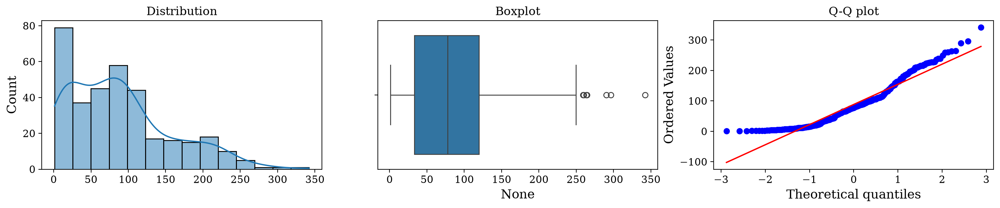

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(19, 3))

sns.histplot(target, kde=True, ax=axes[0])
axes[0].set_title('Distribution')

sns.boxplot(x=target, ax=axes[1])
axes[1].set_title('Boxplot')

stats.probplot(target, dist="norm", plot=axes[2])
axes[2].set_title('Q-Q plot')
plt.savefig('figure_1.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [13]:
target_log = np.log(target)  
target_boxcox, lambda_opt = boxcox(target)  
print("Skewness log:", skew(target_log))
print("Skewness Box-Cox:", skew(target_boxcox))
print("Box-Cox:lambda_opt", lambda_opt)
y_transformed = np.sqrt(target)
print("Skewness sqrt:", skew(y_transformed))

Skewness log: -1.0920409275160816
Skewness Box-Cox: -0.13812406645462225
Box-Cox:lambda_opt 0.41337633324510215
Skewness sqrt: 0.029594099506751792


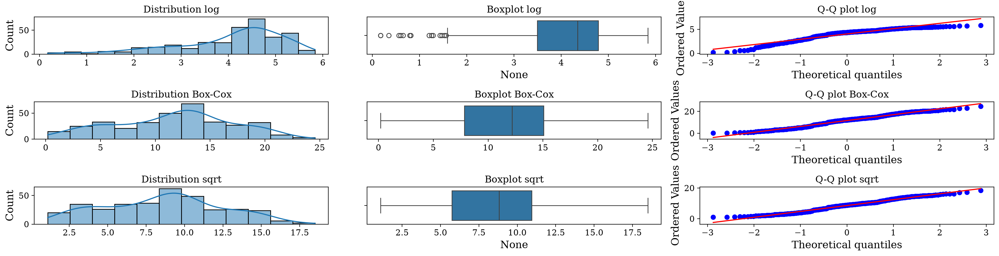

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(19, 5))
sns.histplot(target_log, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribution log')
sns.boxplot(x=target_log, ax=axes[0, 1])
axes[0, 1].set_title('Boxplot log')
stats.probplot(target_log, dist="norm", plot=axes[0, 2])
axes[0, 2].set_title('Q-Q plot log')
sns.histplot(target_boxcox, kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Distribution Box-Cox')
sns.boxplot(x=target_boxcox, ax=axes[1, 1])
axes[1, 1].set_title('Boxplot Box-Cox')
stats.probplot(target_boxcox, dist="norm", plot=axes[1, 2])
axes[1, 2].set_title('Q-Q plot Box-Cox')
sns.histplot(y_transformed, kde=True, ax=axes[2, 0])
axes[2, 0].set_title('Distribution sqrt')
sns.boxplot(x=y_transformed, ax=axes[2, 1])
axes[2, 1].set_title('Boxplot sqrt')
stats.probplot(y_transformed, dist="norm", plot=axes[2, 2])
axes[2, 2].set_title('Q-Q plot sqrt')
plt.tight_layout()
plt.show()

#### Fingerprint and Autocorrelation

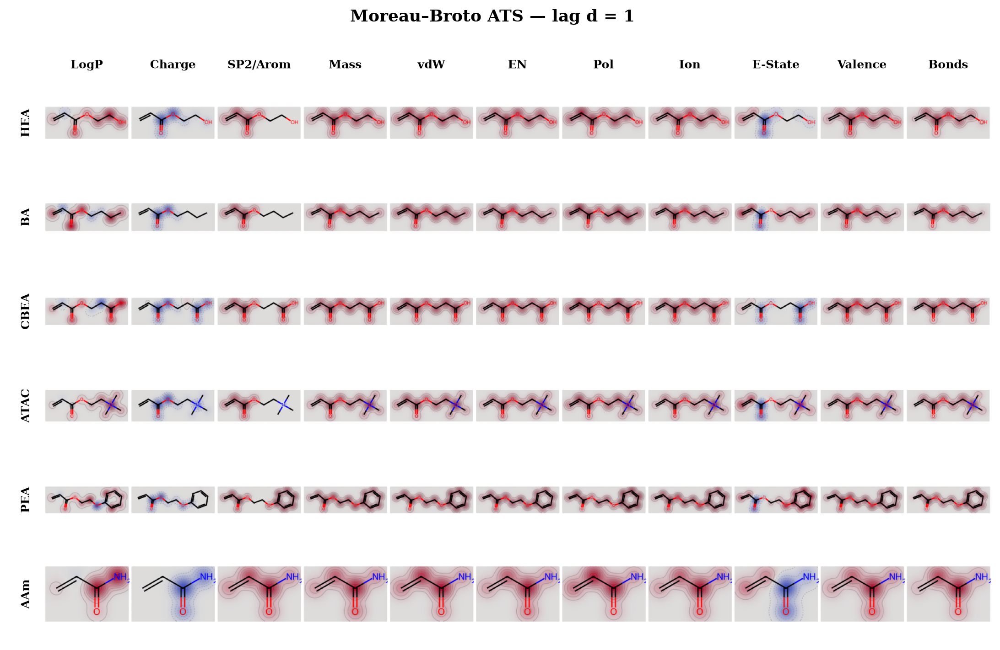

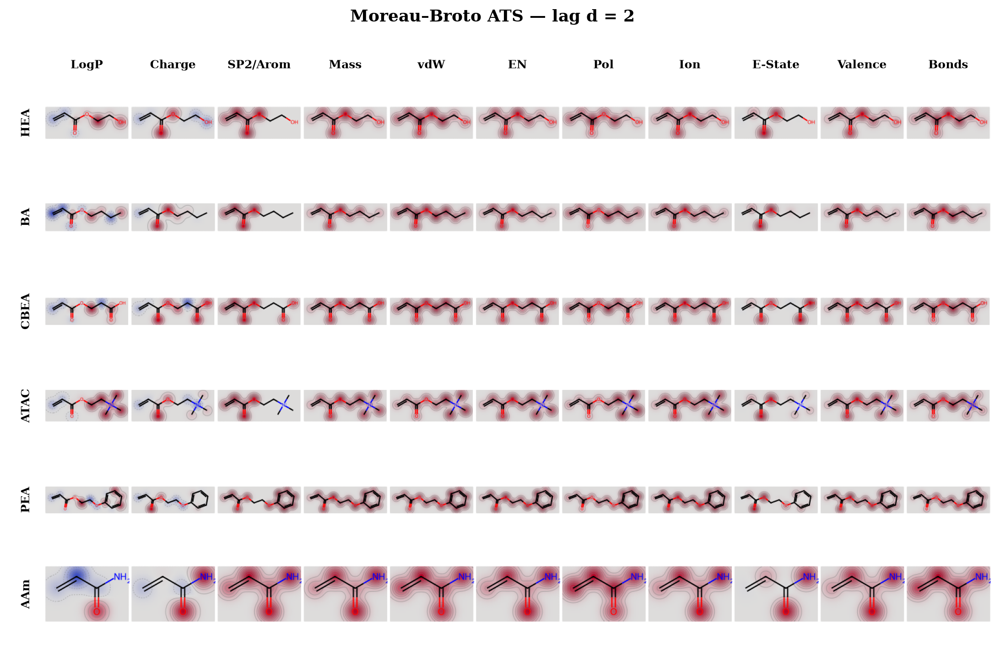

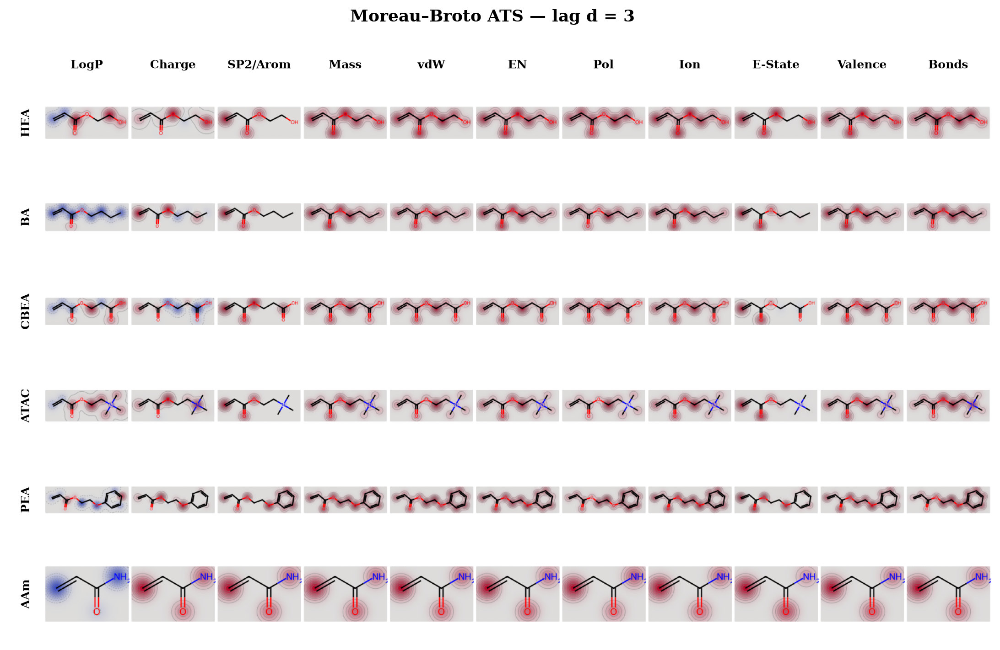

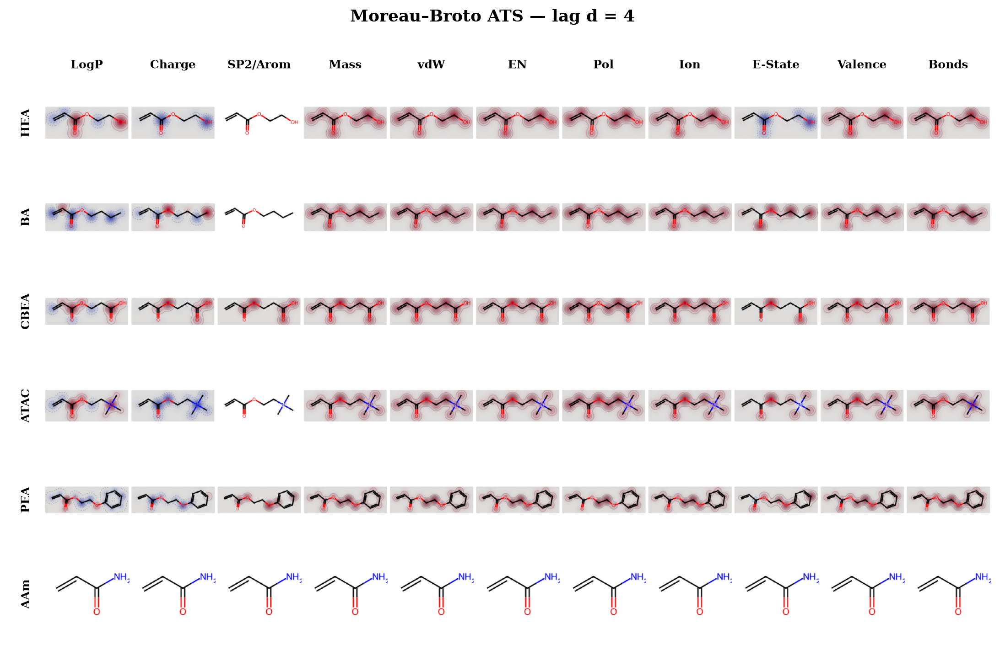

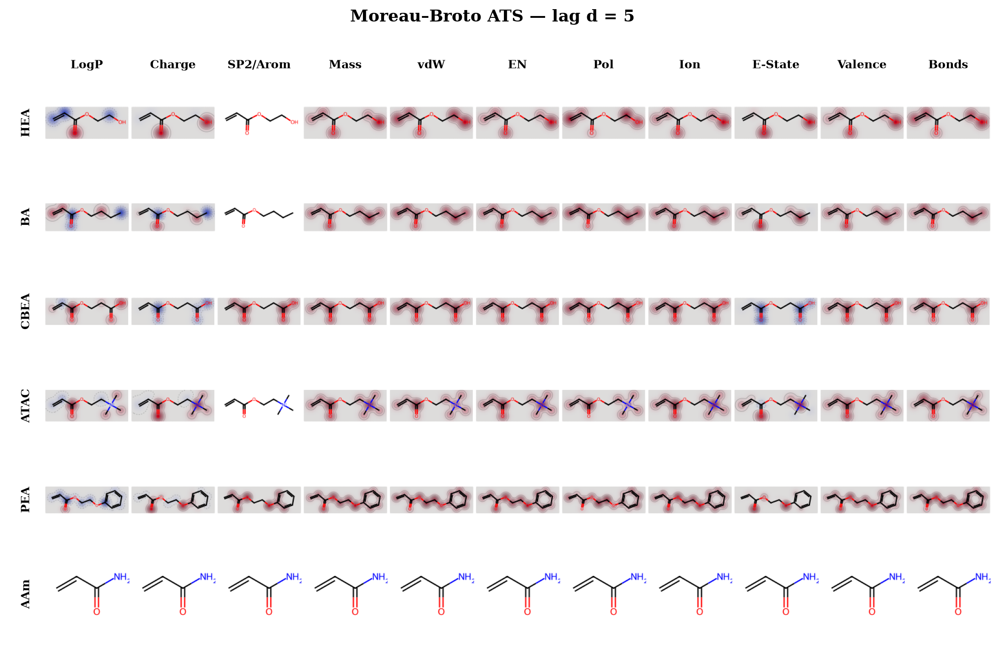

...

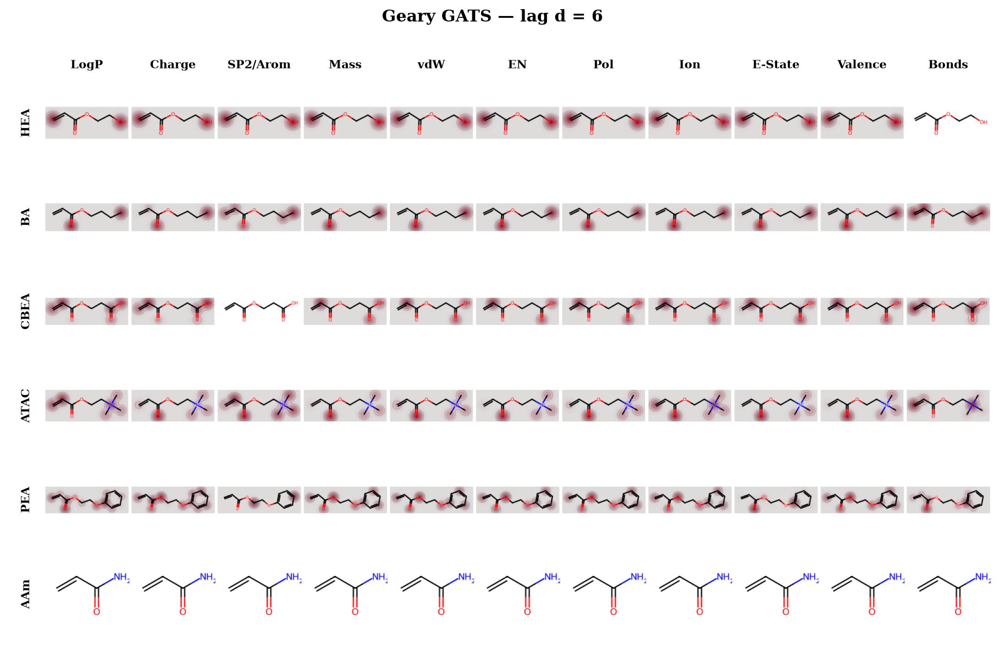

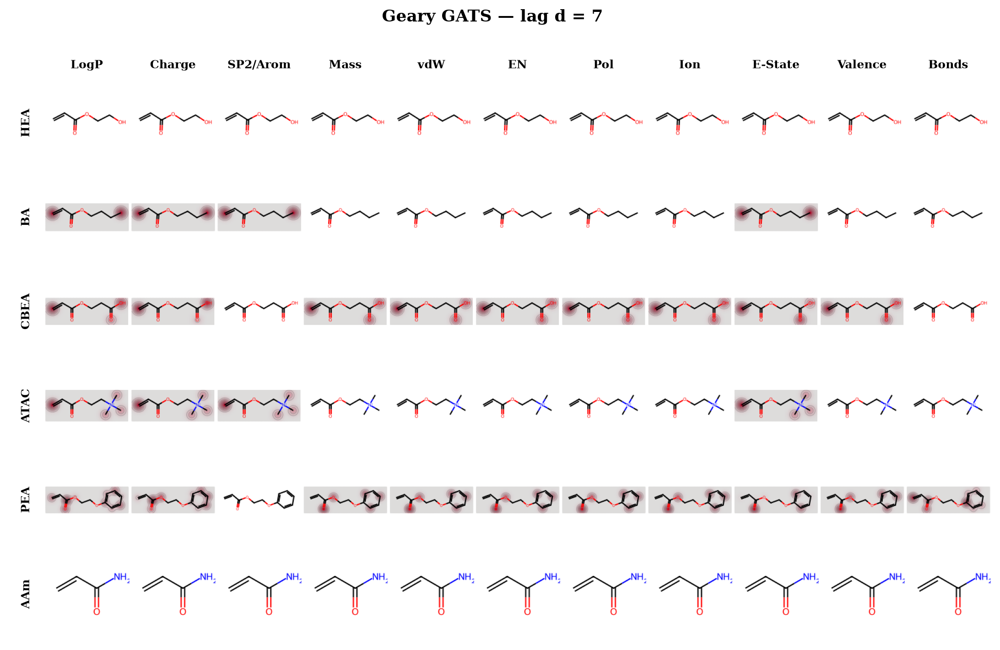

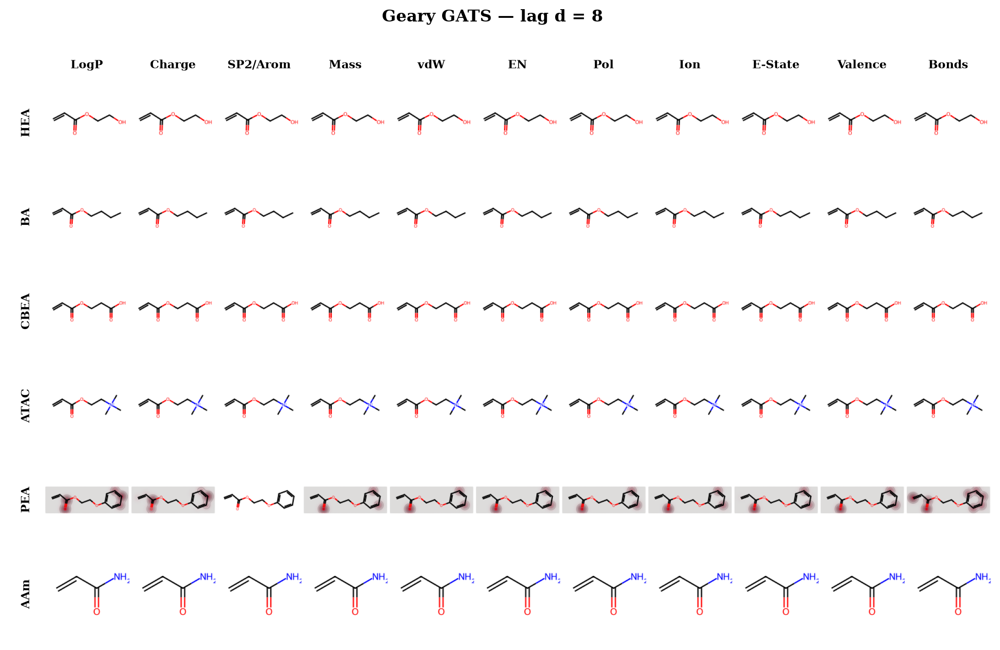

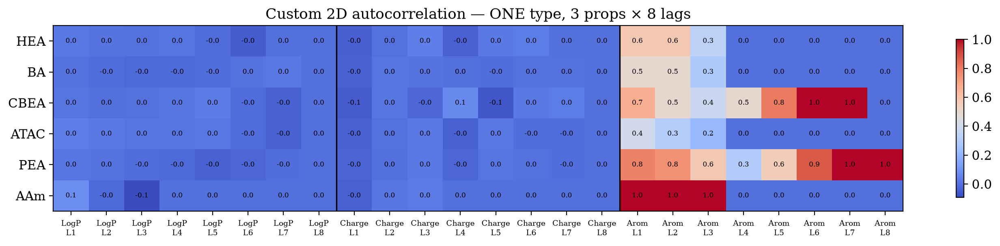

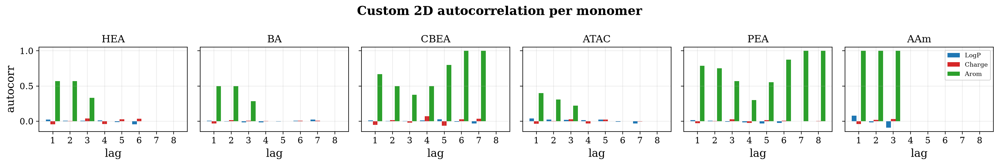

In [18]:
P = Chem.GetPeriodicTable()
D = dict(H=(1.2,2.59,.66,13.6), C=(1.7,2.75,1.76,11.26), N=(1.55,3.19,1.10,14.53),
         O=(1.52,3.65,.80,13.61), F=(1.47,4.,.56,17.42), P=(1.8,2.52,3.63,10.48),
         S=(1.8,2.96,2.90,10.36), Cl=(1.75,3.48,2.18,12.97))
PROPS = ["LogP","Charge","SP2/Arom","Mass","vdW","EN","Pol","Ion","E-State","Valence","Bonds"]
CUSTOM_PROPS = ["LogP","Charge","Arom"]

def prep(mol):
    m = Chem.Mol(mol); rdPartialCharges.ComputeGasteigerCharges(m); rdDepictor.Compute2DCoords(m)
    A = list(m.GetAtoms()); G = lambda k, d: np.array([D.get(a.GetSymbol(),(0,0,0,0))[k] if a.GetSymbol() in D else d for a in A], np.float32)
    return m, rdmolops.GetDistanceMatrix(m), [
        np.array([c[0] for c in MD._CalcCrippenContribs(m)], np.float32),
        np.array([float(a.GetProp('_GasteigerCharge')) if a.HasProp('_GasteigerCharge') else 0. for a in A], np.float32),
        np.array([a.GetIsAromatic() or a.GetHybridization()==Chem.HybridizationType.SP2 for a in A], np.float32),
        np.array([a.GetMass() for a in A], np.float32),
        np.array([4/3*np.pi*D.get(a.GetSymbol(),(1.7,))[0]**3 for a in A], np.float32),
        G(1,2.5), G(2,1.), G(3,10.),
        np.array(EStateIndices(m), np.float32),
        np.array([P.GetNOuterElecs(a.GetAtomicNum()) for a in A], np.float32),
        np.array([len(a.GetBonds()) for a in A], np.float32)]
D2 = [prep(m) for m in mon_mols]; R, C = len(D2), len(PROPS)

def render(mol, w):
    d = rdMolDraw2D.MolDraw2DSVG(140, 140); d.drawOptions().padding = .02
    SimilarityMaps.GetSimilarityMapFromWeights(mol, list(map(float, w)), d, colorMap="coolwarm")
    d.FinishDrawing()
    return np.array(Image.open(io.BytesIO(cairosvg.svg2png(bytestring=d.GetDrawingText()))))

def show(title, fn):
    fig = plt.figure(figsize=(C, 1.1*R + .6))
    gs = fig.add_gridspec(R+1, C+1, width_ratios=[.4]+[1]*C, height_ratios=[.22]+[1]*R,
                          wspace=.01, hspace=.01, left=.02, right=.995, top=.90, bottom=.01)
    for j, n in enumerate(PROPS):
        ax = fig.add_subplot(gs[0, j+1]); ax.axis('off')
        ax.text(.5, .5, n, ha='center', va='center', fontsize=9, fontweight='bold')
    for i, n in enumerate(monomer_names):
        ax = fig.add_subplot(gs[i+1, 0]); ax.axis('off')
        ax.text(.5, .5, n, ha='center', va='center', fontsize=9, fontweight='bold', rotation=90)
    for i, (mol, dm, arr) in enumerate(D2):
        for j in range(C):
            ax = fig.add_subplot(gs[i+1, j+1]); ax.axis('off'); ax.imshow(render(mol, fn(arr[j], dm)))
    fig.suptitle(title, fontsize=13, fontweight='bold', y=.97); plt.show()
M = lambda dm, L: (dm == L).astype(np.float32)
for t, f in {"Moreau–Broto ATS": lambda a,m: a*(m@a),
             "Normalized ATS":   lambda a,m: a*(m@a)/np.maximum(m.sum(1),1),
             "Moran MATS":       lambda a,m: (a-a.mean())*(m@(a-a.mean())),
             "Geary GATS":       lambda a,m: (m*(a[:,None]-a[None,:])**2).sum(1)}.items():
    for L in range(1, 9): show(f"{t} — lag d = {L}", lambda a, dm, f=f, L=L: f(a, M(dm, L)))
def custom(mol, lags=8):
    if mol is None or mol.GetNumAtoms() < 2: return np.zeros(len(CUSTOM_PROPS)*lags, np.float32)
    m = Chem.Mol(mol); rdPartialCharges.ComputeGasteigerCharges(m)
    dm = rdmolops.GetDistanceMatrix(m); A = list(m.GetAtoms())
    arrs = [np.array([c[0] for c in MD._CalcCrippenContribs(m)], np.float32),
            np.array([float(a.GetProp('_GasteigerCharge')) if a.HasProp('_GasteigerCharge') else 0. for a in A], np.float32),
            np.array([a.GetIsAromatic() or a.GetHybridization()==Chem.HybridizationType.SP2 for a in A], np.float32)]
    out = []
    for p in arrs:
        for L in range(1, lags+1):
            i, j = np.where(np.triu(dm == L, 1))
            out.append(0. if not len(i) else float((p[i]*p[j]).sum()/len(i)))
    return np.array(out, np.float32)

V = np.stack([custom(m) for m in mon_mols])
labs = [f"{p}\nL{l}" for p in CUSTOM_PROPS for l in range(1,9)]

fig, ax = plt.subplots(figsize=(14, 3.2)); im = ax.imshow(V, aspect='auto', cmap='coolwarm')
ax.set(xticks=range(24), xticklabels=labs, yticks=range(R), yticklabels=monomer_names,
       title="Custom 2D autocorrelation — ONE type, 3 props × 8 lags")
for t in ax.get_xticklabels(): t.set(fontsize=7)
for k in range(8, 24, 8): ax.axvline(k-.5, color='k', lw=1.2)
for (i,j), v in np.ndenumerate(V): ax.text(j, i, f"{v:.1f}", ha='center', va='center', fontsize=6)
plt.colorbar(im, ax=ax, shrink=.85); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, R, figsize=(3*R, 3), sharey=True); x = np.arange(8); w = .27
for ax, n, v in zip(axs, monomer_names, V):
    for k, (c, lbl) in enumerate(zip(['#1f77b4','#d62728','#2ca02c'], CUSTOM_PROPS)):
        ax.bar(x+(k-1)*w, v[k*8:(k+1)*8], w, color=c, label=lbl)
    ax.set(title=n, xticks=x, xticklabels=range(1,9), xlabel='lag'); ax.grid(alpha=.25)
axs[0].set_ylabel('autocorr'); axs[-1].legend(fontsize=8)
plt.suptitle("Custom 2D autocorrelation per monomer", fontweight='bold')
plt.tight_layout(); plt.show()

ArgumentError: Python argument types in
    None.PrepareAndDrawMolecule(MolDraw2DSVG, Mol)
did not match C++ signature:
    PrepareAndDrawMolecule(RDKit::MolDraw2D {lvalue} drawer, RDKit::ROMol mol, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > legend='', boost::python::api::object highlightAtoms=None, boost::python::api::object highlightBonds=None, boost::python::api::object highlightAtomColors=None, boost::python::api::object highlightBondColors=None, boost::python::api::object highlightAtomRadii=None, int confId=-1, bool kekulize=True)

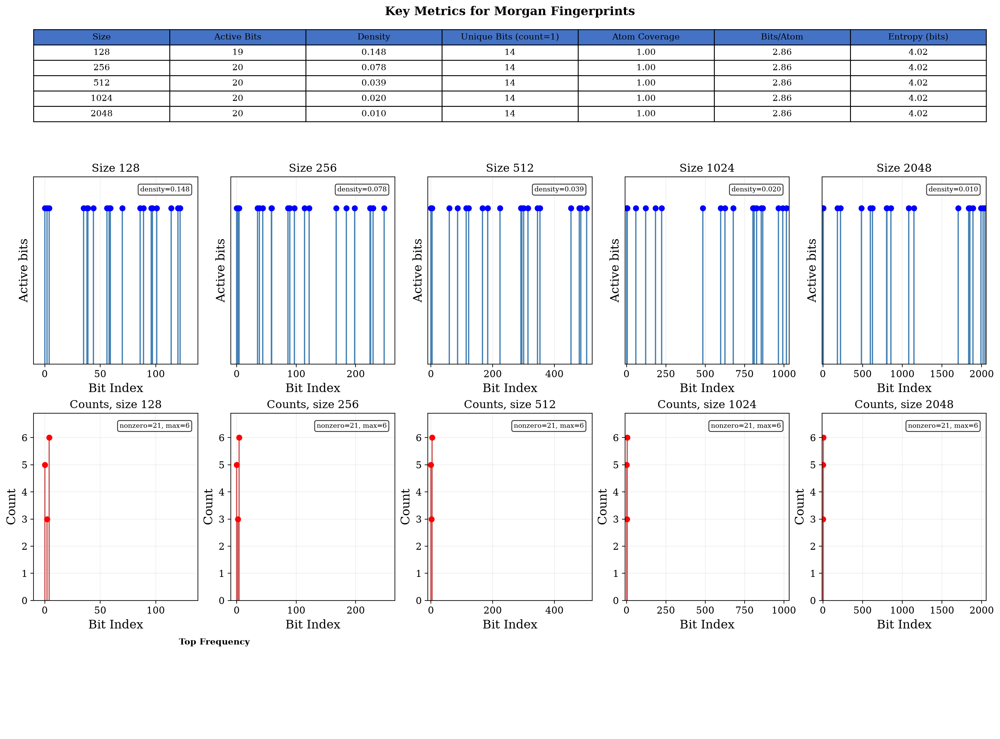

In [19]:
pea_name = 'PEA'
pea_mol = mon_mols[list(v_df.index).index(pea_name)]
rdDepictor.Compute2DCoords(pea_mol)
sizes, R, FEAT = [128, 256, 512, 1024, 2048], 2, True

def fp(n):
    cb = {}
    c = rdMD.GetHashedMorganFingerprint(pea_mol, R, nBits=n, bitInfo=cb, useFeatures=FEAT).GetNonzeroElements()
    return dict(size=n, on_bits=sorted(c), cnt_dict=c, bitInfo_bin=cb)
fps = [fp(s) for s in sizes]

def metrics(d):
    n = pea_mol.GetNumAtoms() or 1
    v = list(d['cnt_dict'].values()) or [1]; p = np.array(v) / sum(v)
    cov = len({a for b in d['on_bits'] for a, _ in d['bitInfo_bin'][b]}) / n
    return cov, sum(len(x) for x in d['bitInfo_bin'].values()) / n, sum(x == 1 for x in v), -np.sum(p * np.log2(p + 1e-12))

def draw_bits(bi, bits, sz=300):
    if not bits: return ''
    pal = [(1,0,0),(0,0,1),(0,.6,0),(.8,.4,0),(.5,0,.5)]
    A, C, Ra = [], {}, {}
    for i, b in enumerate(bits):
        for a, r in bi.get(b, []):
            if a not in A: A.append(int(a)); C[int(a)] = tuple(map(float, pal[i % 5])); Ra[int(a)] = float(r)
    d = rdMolDraw2D.MolDraw2DSVG(sz, sz)
    rdMolDraw2D.PrepareAndDrawMolecule(d, pea_mol, highlightAtoms=A, highlightAtomColors=C, highlightAtomRadii=Ra)
    d.FinishDrawing(); return d.GetDrawingText()

ref = fps[-1]; bi, cnt = ref['bitInfo_bin'], ref['cnt_dict']
tc = [b for b, _ in sorted(cnt.items(), key=lambda x: -x[1])[:3]]
ts = [b for b, _ in sorted(bi.items(), key=lambda x: len(x[1]))[:3]]

fig = plt.figure(figsize=(20, 15)); gs = fig.add_gridspec(4, 5, height_ratios=[.25,.45,.45,.2], hspace=.35)

ax = fig.add_subplot(gs[0, :]); ax.axis('off')
hdr = ['Size','Active Bits','Density','Unique Bits (count=1)','Atom Coverage','Bits/Atom','Entropy (bits)']
rows = [[d['size'], len(d['on_bits']), f"{len(d['on_bits'])/d['size']:.3f}", m[2], f"{m[0]:.2f}", f"{m[1]:.2f}", f"{m[3]:.2f}"]
        for d in fps for m in [metrics(d)]]
t = ax.table(cellText=rows, colLabels=hdr, loc='center', cellLoc='center', colColours=['#4472C4']*7)
t.auto_set_font_size(False); t.set_fontsize(10); t.scale(1, 1.5)
ax.set_title('Key Metrics for Morgan Fingerprints', fontsize=14, fontweight='bold', pad=10)

for i, d in enumerate(fps):
    a = fig.add_subplot(gs[1, i])
    a.stem(d['on_bits'], np.ones_like(d['on_bits']), basefmt=" ", linefmt='steelblue', markerfmt='bo')
    a.set(xlim=(-10, d['size']+10), ylim=(0, 1.2), yticks=[], xlabel='Bit Index', ylabel='Active bits', title=f"Size {d['size']}"); a.grid(alpha=.2)
    a.text(.95, .95, f"density={len(d['on_bits'])/d['size']:.3f}", transform=a.transAxes, ha='right', va='top', fontsize=8, bbox=dict(boxstyle='round', fc='w', alpha=.8))

for i, d in enumerate(fps):
    a = fig.add_subplot(gs[2, i]); it = sorted(d['cnt_dict'].items()); x, y = zip(*it) if it else ([],[])
    a.stem(x, y, basefmt=" ", linefmt='indianred', markerfmt='ro')
    a.set(xlim=(-10, d['size']+10), ylim=(0, (max(y) if y else 1)*1.15), xlabel='Bit Index', ylabel='Count', title=f"Counts, size {d['size']}"); a.grid(alpha=.2)
    a.text(.95, .95, f"nonzero={len(x)}, max={max(y) if y else 0}", transform=a.transAxes, ha='right', va='top', fontsize=8, bbox=dict(boxstyle='round', fc='w', alpha=.8))

def panel(pos, title, bits):
    a = fig.add_subplot(gs[3, pos]); a.axis('off'); a.set_title(title, fontsize=10, fontweight='bold')
    s = draw_bits(bi, bits); lab = '\n'.join(f"Bit {b}: cnt={cnt.get(b,0)}, atoms={len(bi.get(b,[]))}" for b in bits)
    if raster: a.imshow(raster(s)); a.text(.5, -.1, lab, transform=a.transAxes, ha='center', va='top', fontsize=8)
    else: display(HTML(f"<div style='text-align:center'><b>{title}</b><br>{lab.replace(chr(10),'<br>')}</div>")); display(SVG(s))

panel(slice(0, 2), 'Top Frequency', tc); panel(slice(2, 5), 'Top Specificity', ts)
plt.suptitle(f'Morgan Fingerprint Analysis for {pea_name}', fontsize=16, fontweight='bold')
plt.tight_layout(); plt.show()

#### Polymer Analyze




  Dataset Metric  Original_Dim  Variance_per_dim
 autocorr   mean           216          0.145512
 autocorr    std           216          0.136910
cffp_1024   mean          1024          0.002531
cffp_1024    std          1024          0.004137
 cffp_128   mean           128          0.021599
 cffp_128    std           128          0.035110
cffp_2048   mean          2048          0.001265
cffp_2048    std          2048          0.002068
 cffp_256   mean           256          0.010043
 cffp_256    std           256          0.016020
 cffp_512   mean           512          0.005062
 cffp_512    std           512          0.008274
  eMFP128   mean           128          0.000006
  eMFP128    std           128          0.000015
   eMFP16   mean          1024          0.000002
   eMFP16    std          1024          0.000005
   eMFP32   mean           512          0.000004
   eMFP32    std           512          0.000008
   eMFP64   mean           256          0.000005
   eMFP64    std    

In [20]:
import h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.manifold import TSNE

names = ['autocorr','cffp_1024','cffp_128','cffp_2048','cffp_256','cffp_512',
         'eMFP128','eMFP16','eMFP32','eMFP64','ffp_1024','ffp_128','ffp_2048','ffp_256','ffp_512']

with h5py.File('data/poly_datasets.h5','r') as f:
    M = {n: {'mean': f[n][:].mean(1), 'std': f[n][:].std(1)} for n in names}

embed = lambda X: TSNE(2, random_state=42, perplexity=30, max_iter=1000).fit_transform(X) if X.shape[1]>2 \
             else X if X.shape[1]==2 else np.column_stack([X, np.zeros(len(X))])

mets = ['mean','std']
vmin, vmax = np.percentile(adhesion, [2, 98])
fig, ax = plt.subplots(len(names), 2, figsize=(12, 5*len(names)))
for c, m in enumerate(mets):
    ax[0,c].set_title(f'{m} — colored by adhesion', fontsize=12, fontweight='bold')
for r, n in enumerate(names):
    for c, m in enumerate(mets):
        X = embed(M[n][m])
        sc = ax[r,c].scatter(X[:,0], X[:,1], c=adhesion, cmap='coolwarm',
                             vmin=vmin, vmax=vmax, alpha=.75, s=50,
                             edgecolors='black', linewidth=.4)
        ax[r,c].set(xlabel='t-SNE 1', ylabel='t-SNE 2',
                    title=f'{n} — {m}', xticks=[], yticks=[])
        ax[r,c].grid(alpha=.3)
        plt.colorbar(sc, ax=ax[r,c], fraction=.046, pad=.04).set_label('Adhesion (kPa)', fontsize=9)
plt.subplots_adjust(wspace=.25, hspace=.5, left=.05, right=.95, top=.98, bottom=.02); plt.show()

print(pd.DataFrame([[n, m, M[n][m].shape[1], np.var(M[n][m],0).mean()] for n in names for m in mets],
                   columns=['Dataset','Metric','Original_Dim','Variance_per_dim']).to_string(index=False))

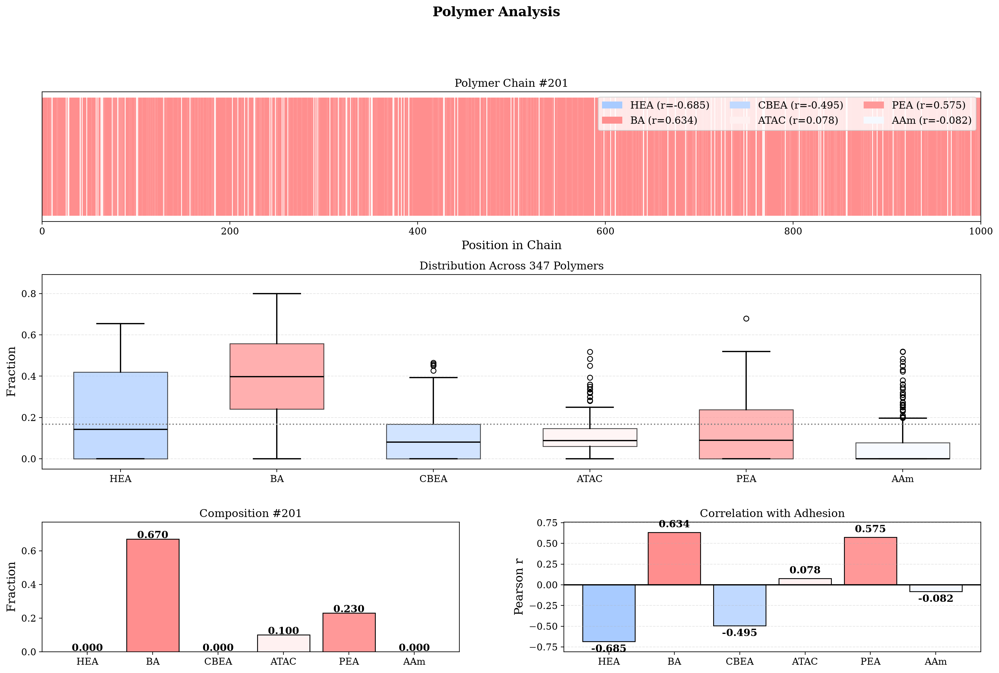

Polymer #201: adhesion=202.86 kPa
  HEA: comp=0.0000 (0.00%) | r=-0.6854 | mean=0.2169 std=0.2090
  BA: comp=0.6700 (67.00%) | r=0.6340 | mean=0.3950 std=0.1808
  CBEA: comp=0.0000 (0.00%) | r=-0.4951 | mean=0.0944 std=0.0996
  ATAC: comp=0.1000 (10.00%) | r=0.0775 | mean=0.1054 std=0.0837
  PEA: comp=0.2300 (23.00%) | r=0.5745 | mean=0.1315 std=0.1391
  AAm: comp=0.0000 (0.00%) | r=-0.0820 | mean=0.0567 std=0.1033


In [21]:
mon = {'HEA':'C=CC(=O)OCCO','BA':'C=CC(=O)OCCCC','CBEA':'C=CC(=O)OCCC(=O)O',
       'ATAC':'C=CC(=O)OCC[N+](C)(C)C','PEA':'C=CC(=O)OCCOc1ccccc1','AAm':'C=CC(=O)N'}
names = list(mon)

def ac2d(mol, L=8):
    if mol is None or mol.GetNumAtoms()<2: return np.zeros(3*L, np.float32)
    m = Chem.Mol(mol); rdPartialCharges.ComputeGasteigerCharges(m)
    dm = rdmolops.GetDistanceMatrix(m); A = list(m.GetAtoms())
    arrs = [np.array([c[0] for c in rdMolDescriptors._CalcCrippenContribs(m)], np.float32),
            np.array([float(a.GetProp('_GasteigerCharge')) if a.HasProp('_GasteigerCharge') else 0. for a in A], np.float32),
            np.array([a.GetIsAromatic() or a.GetHybridization()==Chem.HybridizationType.SP2 for a in A], np.float32)]
    out = []
    for p in arrs:
        for l in range(1, L+1):
            i,j = np.where(np.triu(dm==l, 1))
            out.append(0. if not len(i) else float((p[i]*p[j]).sum()/len(i)))
    return np.array(out, np.float32)

feats = np.array([np.concatenate([ac2d(Chem.MolFromSmiles(s)), rdMolDescriptors.CalcAUTOCORR2D(Chem.MolFromSmiles(s))])
                  for s in mon.values()], np.float32)

with h5py.File('data/poly_datasets.h5','r') as f: D = f['autocorr'][:]

n, L = len(adhesion), 1000
chains = np.zeros((n, L), int); comp = np.zeros((n, 6))
for i in range(n):
    for j in range(L):
        k = next((k for k in range(6) if np.allclose(D[i,j], feats[k], rtol=1e-5, atol=1e-8)), None)
        if k is not None: chains[i,j] = k; comp[i,k] += 1
comp /= L

corr = np.array([pearsonr(comp[:,k], adhesion)[0] for k in range(6)])
col = lambda c: (1., 1.-.7*min(abs(c),1), 1.-.7*min(abs(c),1)) if c>=0 else (1.-.5*min(abs(c),1), 1.-.3*min(abs(c),1), 1.)
colors = [col(c) for c in corr]

idx = 200; seq, cp = chains[idx], comp[idx]
fig = plt.figure(figsize=(20,12))
gs = fig.add_gridspec(3,2, height_ratios=[1,1.5,1], hspace=.35, wspace=.25)

ax0 = fig.add_subplot(gs[0,:])
for i,k in enumerate(seq): ax0.barh(0, 1, left=i, color=colors[k], height=.8)
ax0.set(xlim=(0,L), yticks=[], xlabel='Position in Chain', title=f'Polymer Chain #{idx+1}')
ax0.legend(handles=[Patch(facecolor=colors[i], label=f'{names[i]} (r={corr[i]:.3f})') for i in range(6)], ncol=3)

ax1 = fig.add_subplot(gs[1,:])
bp = ax1.boxplot([comp[:,k] for k in range(6)], patch_artist=True, widths=.6)
for p, c in zip(bp['boxes'], colors): p.set_facecolor(c); p.set_alpha(.7)
for nm, part in bp.items():
    if nm != 'boxes':
        for it in part: it.set(color='black', lw=1.5)
ax1.set(xticklabels=names, ylabel='Fraction', title='Distribution Across 347 Polymers')
ax1.grid(axis='y', alpha=.3, ls='--'); ax1.axhline(1/6, color='gray', ls=':')
ax1.set_ylim(-0.05, max(max(comp.max(0)), 0.85)*1.05)   # ← буфер под подписи

ax2 = fig.add_subplot(gs[2,0])
b2 = ax2.bar(names, cp, color=colors, edgecolor='black')
ax2.set(ylabel='Fraction', title=f'Composition #{idx+1}',
        ylim=(0, max(cp.max(), .01)*1.15))               # ← 15% запаса сверху
for b,v in zip(b2, cp): ax2.text(b.get_x()+b.get_width()/2, b.get_height()+.005, f'{v:.3f}',
                                 ha='center', fontweight='bold', clip_on=False)

ax3 = fig.add_subplot(gs[2,1])
b3 = ax3.bar(names, corr, color=colors, edgecolor='black')
ax3.set(ylabel='Pearson r', title='Correlation with Adhesion')
ax3.axhline(0, color='black'); ax3.grid(axis='y', alpha=.3, ls='--')
pad = max(abs(corr).max(), .01) * .18
ax3.set_ylim(min(corr.min()-pad, -pad), max(corr.max()+pad, pad))   # ← запас сверху и снизу
for b,v in zip(b3, corr):
    ax3.text(b.get_x()+b.get_width()/2, v + (pad*.25 if v>=0 else -pad*.25), f'{v:.3f}',
             ha='center', va='bottom' if v>=0 else 'top', fontweight='bold', clip_on=False)

plt.suptitle('Polymer Analysis', fontweight='bold', y=.998); plt.show()

print(f"Polymer #{idx+1}: adhesion={adhesion[idx]:.2f} kPa")
for i, nm in enumerate(names):
    print(f"  {nm}: comp={cp[i]:.4f} ({cp[i]*100:.2f}%) | r={corr[i]:.4f} | mean={comp[:,i].mean():.4f} std={comp[:,i].std():.4f}")

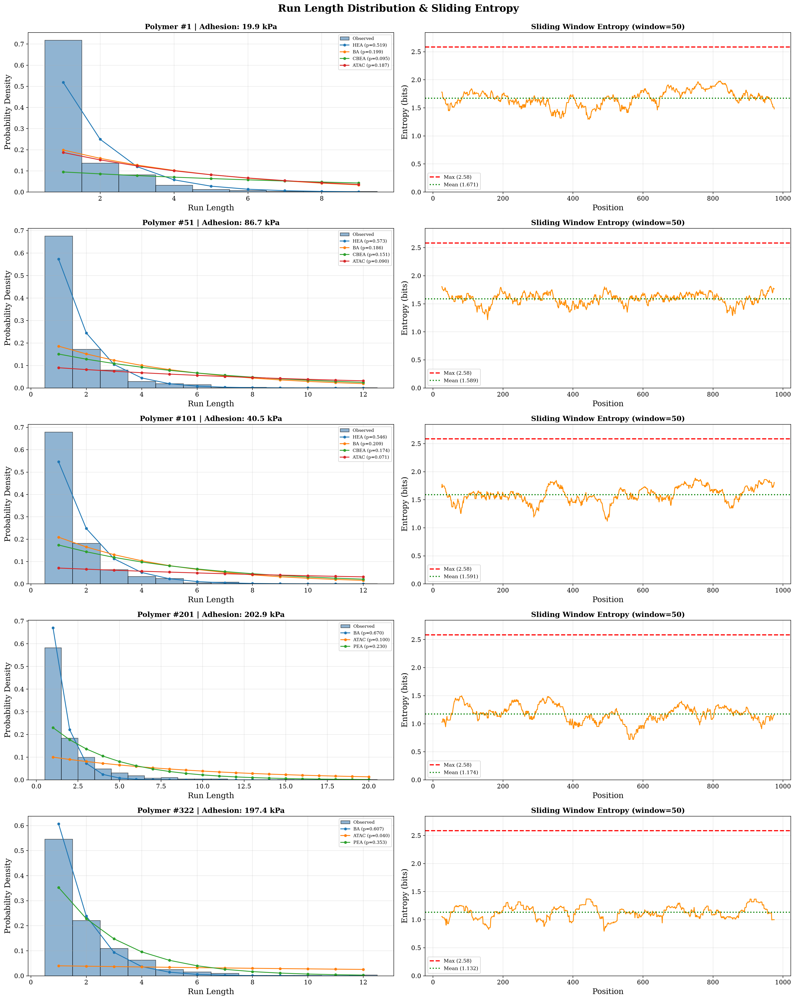

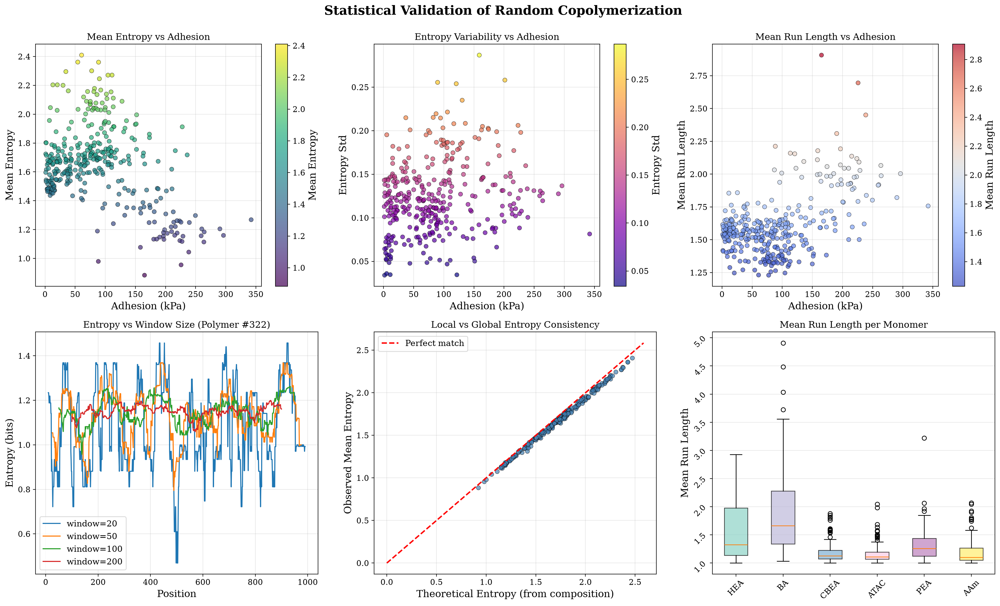


RANDOM POLYMERIZATION VALIDATION REPORT

1. Entropy Analysis:
   Mean entropy: 1.6573 bits
   Max theoretical: 2.5850 bits
   Efficiency: 64.11%
   Entropy variability (mean std): 0.1243 bits

2. Run Length Analysis:
   Mean run length: 1.605 ± 0.229

3. Per-Monomer Run Statistics:
   HEA   : mean=1.531 ± 0.468
   BA    : mean=1.835 ± 0.643
   CBEA  : mean=1.172 ± 0.156
   ATAC  : mean=1.152 ± 0.135
   PEA   : mean=1.307 ± 0.247
   AAm   : mean=1.193 ± 0.224

4. Correlation with Adhesion:
   Adhesion vs Mean Entropy: -0.3856
   Adhesion vs Entropy Std: 0.2076
   Adhesion vs Mean Run Length: 0.4993


In [22]:
with h5py.File('data/poly_datasets.h5', 'r') as f:
    autocorr_data = f['autocorr'][:]

def custom_autocorr(mol, lags=8):
    if mol is None or mol.GetNumAtoms()<2: return np.zeros(3*lags, dtype=np.float32)
    mc = Chem.Mol(mol)
    rdPartialCharges.ComputeGasteigerCharges(mc)
    dm = rdmolops.GetDistanceMatrix(mc)
    contribs = rdMolDescriptors._CalcCrippenContribs(mc)
    logp = np.array([c[0] for c in contribs], dtype=np.float32)
    charge = np.array([float(a.GetProp('_GasteigerCharge')) if a.HasProp('_GasteigerCharge') else 0.0 for a in mc.GetAtoms()], dtype=np.float32)
    arom = np.array([1.0 if a.GetIsAromatic() or a.GetHybridization()==Chem.HybridizationType.SP2 else 0.0 for a in mc.GetAtoms()], dtype=np.float32)
    vec = []
    for arr in [logp, charge, arom]:
        for lag in range(1,lags+1):
            mask = np.triu(dm==lag, k=1)
            i,j = np.where(mask)
            vec.append(0.0 if len(i)==0 else np.sum(arr[i]*arr[j])/len(i))
    return np.array(vec, dtype=np.float32)

mon_mols = [Chem.MolFromSmiles(s) for s in monomers.values()]
mon_features = np.array([np.concatenate([custom_autocorr(m,8), rdMolDescriptors.CalcAUTOCORR2D(m)]) for m in mon_mols], dtype=np.float32)
n_mon = len(mon_features)

def get_sequence(idx):
    chain = autocorr_data[idx]
    seq = []
    for feat in chain:
        dists = np.linalg.norm(mon_features - feat, axis=1)
        seq.append(np.argmin(dists))
    return np.array(seq)

def run_lengths(seq):
    rl = {k: [] for k in range(n_mon)}
    if len(seq)==0: return rl
    cur, cnt = seq[0], 1
    for x in seq[1:]:
        if x==cur: cnt+=1
        else: rl[cur].append(cnt); cur, cnt = x, 1
    rl[cur].append(cnt)
    return rl

def sliding_entropy(seq, w=50):
    n = len(seq)
    pos, ent = [], []
    for i in range(n - w + 1):
        window = seq[i:i+w]
        counts = np.bincount(window, minlength=n_mon)
        probs = counts / w
        ent.append(-np.sum(probs * np.log2(probs + 1e-12)))
        pos.append(i + w//2)
    return np.array(pos), np.array(ent)

def geom_run_dist(p, L=20):
    x = np.arange(1, L+1)
    return x, p * (1-p)**(x-1)

inds = [0, 50, 100, 200, 321]
fig1, axes1 = plt.subplots(len(inds), 2, figsize=(20, 5*len(inds)))
fig1.suptitle('Run Length Distribution & Sliding Entropy', fontsize=18, fontweight='bold', y=0.995)
for i, idx in enumerate(inds):
    seq = get_sequence(idx)
    rl = run_lengths(seq)
    comp = np.bincount(seq, minlength=n_mon) / len(seq)
    all_runs = [v for vals in rl.values() for v in vals]
    if all_runs:
        max_r = max(all_runs)
        bins = np.arange(0.5, max_r+1.5, 1)
        axes1[i,0].hist(all_runs, bins=bins, density=True, alpha=0.6, color='steelblue', edgecolor='black', label='Observed')
        L_plot = np.arange(1, max_r+1)
        for k in range(n_mon):
            if comp[k] > 0.01:
                _, theo = geom_run_dist(comp[k], max_r)
                axes1[i,0].plot(L_plot, theo, 'o-', label=f'{mon_names[k]} (p={comp[k]:.3f})', markersize=4, linewidth=1.5)
        axes1[i,0].set_xlabel('Run Length'); axes1[i,0].set_ylabel('Probability Density')
        axes1[i,0].set_title(f'Polymer #{idx+1} | Adhesion: {adhesion[idx]:.1f} kPa', fontweight='bold')
        axes1[i,0].legend(fontsize=8); axes1[i,0].grid(True, alpha=0.3)
    pos, ent = sliding_entropy(seq, 50)
    axes1[i,1].plot(pos, ent, color='darkorange', lw=1.5)
    axes1[i,1].axhline(np.log2(n_mon), color='red', ls='--', lw=2, label=f'Max ({np.log2(n_mon):.2f})')
    axes1[i,1].axhline(np.mean(ent), color='green', ls=':', lw=2, label=f'Mean ({np.mean(ent):.3f})')
    axes1[i,1].set_xlabel('Position'); axes1[i,1].set_ylabel('Entropy (bits)')
    axes1[i,1].set_title('Sliding Window Entropy (window=50)', fontweight='bold')
    axes1[i,1].legend(fontsize=9); axes1[i,1].grid(True, alpha=0.3)
    axes1[i,1].set_ylim(0, np.log2(n_mon)*1.1)
plt.tight_layout()
plt.show()

N = len(adhesion)
seqs = [get_sequence(i) for i in range(N)]
rl_all = [run_lengths(s) for s in seqs]
comp_all = np.array([np.bincount(s, minlength=n_mon)/len(s) for s in seqs])
mean_ent = []; std_ent = []; mean_run = []
for i in range(N):
    _, ent = sliding_entropy(seqs[i], 50)
    mean_ent.append(np.mean(ent)); std_ent.append(np.std(ent))
    runs = [v for vals in rl_all[i].values() for v in vals]
    mean_run.append(np.mean(runs) if runs else 0)
mean_ent = np.array(mean_ent); std_ent = np.array(std_ent); mean_run = np.array(mean_run)

fig2, axes2 = plt.subplots(2, 3, figsize=(20,12))
fig2.suptitle('Statistical Validation of Random Copolymerization', fontsize=18, fontweight='bold', y=0.995)
sc1 = axes2[0,0].scatter(adhesion, mean_ent, c=mean_ent, cmap='viridis', alpha=0.7, edgecolors='black', lw=0.5)
axes2[0,0].set_xlabel('Adhesion (kPa)'); axes2[0,0].set_ylabel('Mean Entropy')
axes2[0,0].set_title('Mean Entropy vs Adhesion'); axes2[0,0].grid(True, alpha=0.3); plt.colorbar(sc1, ax=axes2[0,0], label='Mean Entropy')
sc2 = axes2[0,1].scatter(adhesion, std_ent, c=std_ent, cmap='plasma', alpha=0.7, edgecolors='black', lw=0.5)
axes2[0,1].set_xlabel('Adhesion (kPa)'); axes2[0,1].set_ylabel('Entropy Std')
axes2[0,1].set_title('Entropy Variability vs Adhesion'); axes2[0,1].grid(True, alpha=0.3); plt.colorbar(sc2, ax=axes2[0,1], label='Entropy Std')
sc3 = axes2[0,2].scatter(adhesion, mean_run, c=mean_run, cmap='coolwarm', alpha=0.7, edgecolors='black', lw=0.5)
axes2[0,2].set_xlabel('Adhesion (kPa)'); axes2[0,2].set_ylabel('Mean Run Length')
axes2[0,2].set_title('Mean Run Length vs Adhesion'); axes2[0,2].grid(True, alpha=0.3); plt.colorbar(sc3, ax=axes2[0,2], label='Mean Run Length')
sample_seq = seqs[321]
for ws in [20, 50, 100, 200]:
    pos, ent = sliding_entropy(sample_seq, ws)
    axes2[1,0].plot(pos, ent, label=f'window={ws}', lw=1.5)
axes2[1,0].set_xlabel('Position'); axes2[1,0].set_ylabel('Entropy (bits)')
axes2[1,0].set_title(f'Entropy vs Window Size (Polymer #322)'); axes2[1,0].legend(); axes2[1,0].grid(alpha=0.3)
theo_ent = np.array([-np.sum(p*np.log2(p+1e-12)) for p in comp_all])
axes2[1,1].scatter(theo_ent, mean_ent, alpha=0.7, edgecolors='black', lw=0.5, color='steelblue')
axes2[1,1].plot([0, np.log2(6)], [0, np.log2(6)], 'r--', lw=2, label='Perfect match')
axes2[1,1].set_xlabel('Theoretical Entropy (from composition)'); axes2[1,1].set_ylabel('Observed Mean Entropy')
axes2[1,1].set_title('Local vs Global Entropy Consistency'); axes2[1,1].legend(); axes2[1,1].grid(alpha=0.3)
mean_runs_mon = {k: [] for k in range(n_mon)}
for rl_dict in rl_all:
    for k, v in rl_dict.items():
        if v: mean_runs_mon[k].append(np.mean(v))
bp = axes2[1,2].boxplot([mean_runs_mon[k] for k in range(n_mon)], patch_artist=True)
axes2[1,2].set_xticklabels(mon_names)
cols = plt.cm.Set3(np.linspace(0,1,n_mon))
for patch,c in zip(bp['boxes'], cols): patch.set_facecolor(c); patch.set_alpha(0.7)
axes2[1,2].set_ylabel('Mean Run Length'); axes2[1,2].set_title('Mean Run Length per Monomer'); axes2[1,2].grid(axis='y', alpha=0.3); axes2[1,2].tick_params(rotation=45)
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("RANDOM POLYMERIZATION VALIDATION REPORT")
print("="*70)
print(f"\n1. Entropy Analysis:")
print(f"   Mean entropy: {np.mean(mean_ent):.4f} bits")
print(f"   Max theoretical: {np.log2(n_mon):.4f} bits")
print(f"   Efficiency: {np.mean(mean_ent)/np.log2(n_mon)*100:.2f}%")
print(f"   Entropy variability (mean std): {np.mean(std_ent):.4f} bits")
print(f"\n2. Run Length Analysis:")
print(f"   Mean run length: {np.mean(mean_run):.3f} ± {np.std(mean_run):.3f}")
print(f"\n3. Per-Monomer Run Statistics:")
for k in range(n_mon):
    if mean_runs_mon[k]:
        vals = mean_runs_mon[k]
        print(f"   {mon_names[k]:6s}: mean={np.mean(vals):.3f} ± {np.std(vals):.3f}")
print(f"\n4. Correlation with Adhesion:")
for name, var in [('Mean Entropy', mean_ent), ('Entropy Std', std_ent), ('Mean Run Length', mean_run)]:
    corr = np.corrcoef(adhesion, var)[0,1]
    print(f"   Adhesion vs {name}: {corr:.4f}")
print("="*70)

#### After downscaling

In [23]:
y = np.asarray(adhesion).ravel()

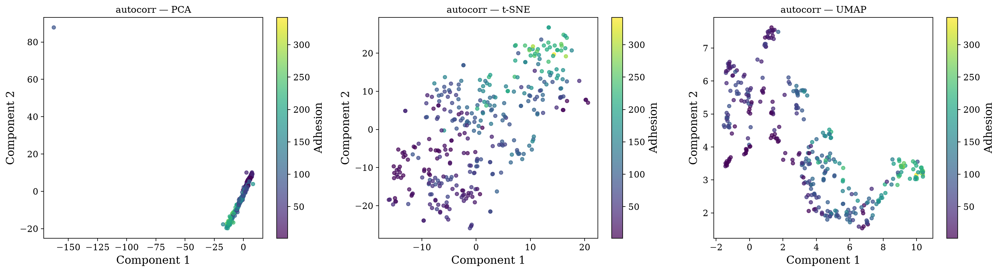

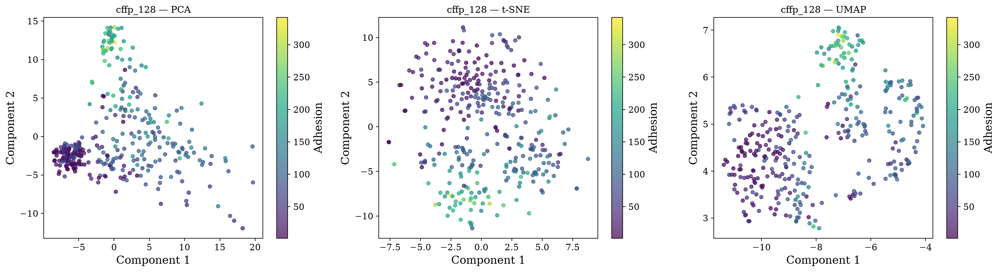

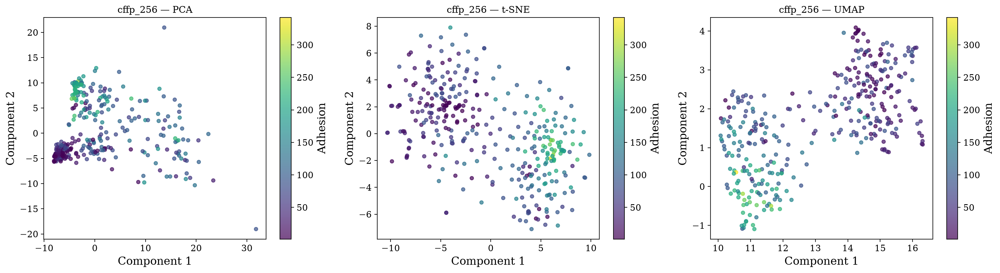

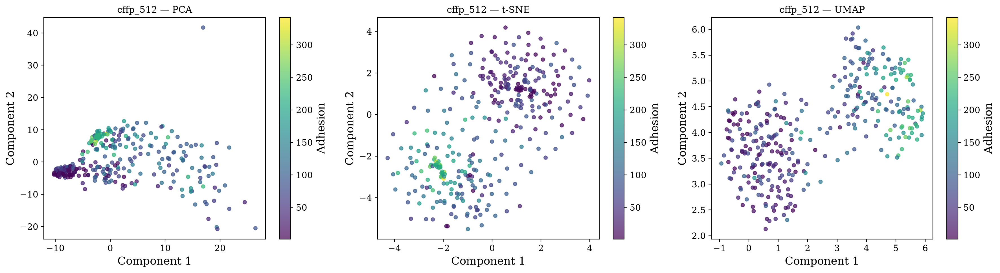

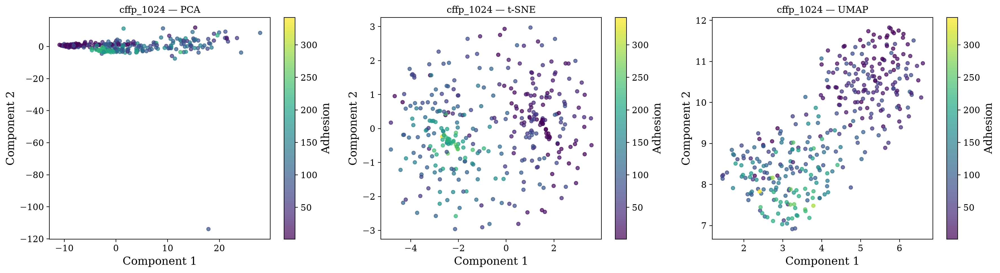

...

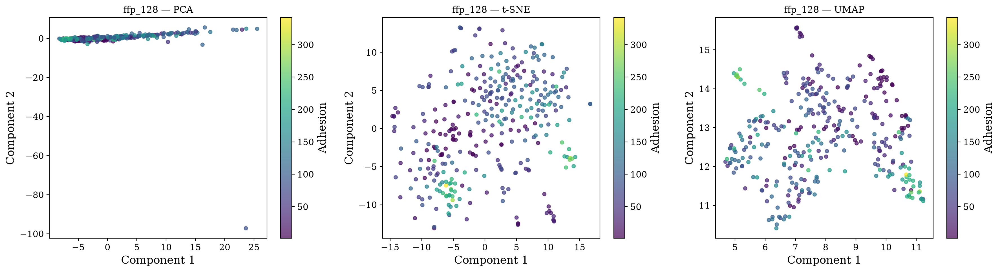

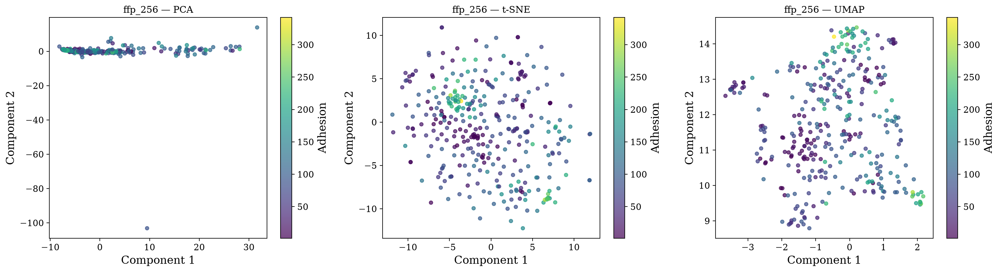

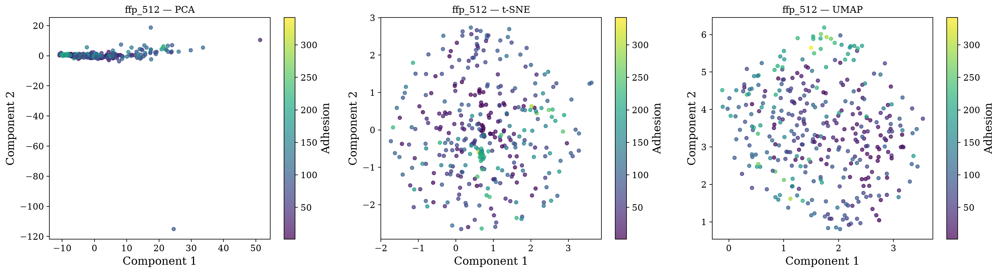

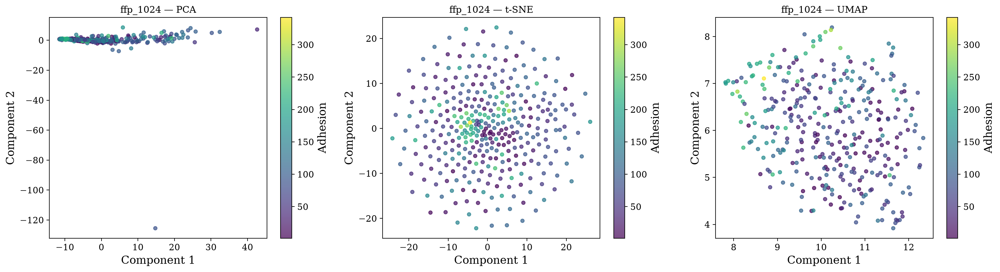

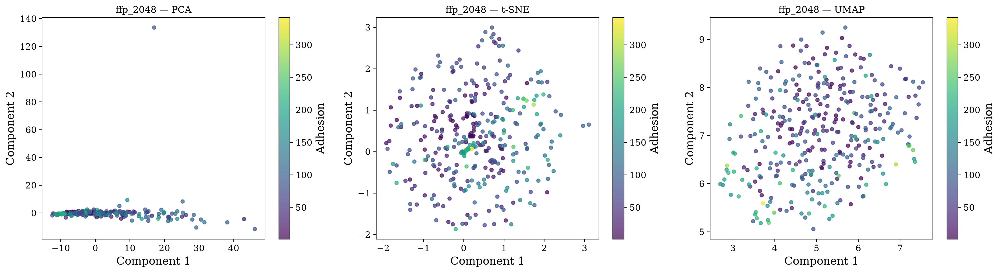

In [24]:
names = ['autocorr', 'cffp_128', 'cffp_256', 'cffp_512', 'cffp_1024', 'cffp_2048', 'eMFP16', 'eMFP32', 'eMFP64', 'eMFP128', 
         'ffp_128', 'ffp_256', 'ffp_512', 'ffp_1024', 'ffp_2048']


for name in names:
    try:
        X = np.load(f'./data/ML/npys/{name}_compressed.npy')
    except FileNotFoundError:
        print(f"File {name}_compressed.npy not found. Skipping.")
        continue
    if X.shape[0] != len(y):
        print(f"Warning: {name} has {X.shape[0]} samples, but adhesion has {len(y)}. Skipping.")
        continue
    X_scaled = StandardScaler().fit_transform(X)
    pca = PCA(n_components=2).fit_transform(X_scaled)
    tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=500).fit_transform(X_scaled)
    fig, axes = plt.subplots(1, 3, figsize=(18,5))
    umap_proj = umap.UMAP(random_state=42).fit_transform(X_scaled)
    proj_list = [pca, tsne, umap_proj]
    titles = ['PCA','t-SNE','UMAP']
    for ax, proj, ttl in zip(axes, proj_list, titles):
        sc = ax.scatter(proj[:,0], proj[:,1], c=y, cmap='viridis', alpha=0.7, s=20)
        ax.set_title(f'{name} — {ttl}', fontsize=12)
        ax.set_xlabel('Component 1')
        ax.set_ylabel('Component 2')
        plt.colorbar(sc, ax=ax, label='Adhesion')
    plt.tight_layout()
    plt.show()

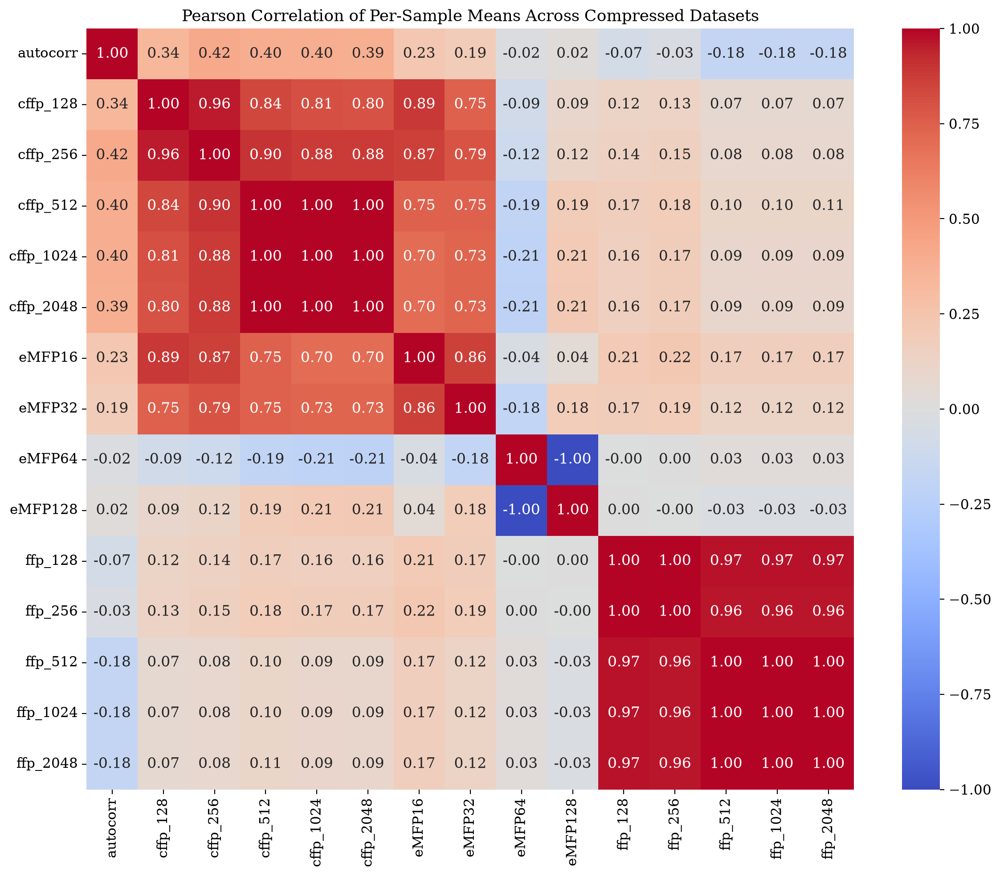

In [25]:
names = ['autocorr', 'cffp_128', 'cffp_256', 'cffp_512', 'cffp_1024', 'cffp_2048', 'eMFP16', 'eMFP32', 'eMFP64', 'eMFP128', 
         'ffp_128', 'ffp_256', 'ffp_512', 'ffp_1024', 'ffp_2048']

loaded = []
valid_names = []
for n in names:
    p = Path(f'./data/ML/npys/{n}_compressed.npy')
    if p.exists():
        loaded.append(np.load(p).mean(axis=1, dtype=np.float64))
        valid_names.append(n)

corr = np.corrcoef(loaded)
plt.figure(figsize=(12,10))
sns.heatmap(corr, xticklabels=valid_names, yticklabels=valid_names, annot=True,
            cmap='coolwarm', center=0, vmin=-1, vmax=1, fmt='.2f')
plt.title('Pearson Correlation of Per‑Sample Means Across Compressed Datasets')
plt.tight_layout()
plt.show()

## Test on Models 

#### Save

In [3]:
def save_model_data(model_name, plot_data, filename='./data/ML/models/results.json'):
    data = {}
    if os.path.exists(filename):
        with open(filename, 'r') as f:
            data = json.load(f)
            
    data[model_name] = plot_data
    
    with open(filename, 'w') as f:
        json.dump(data, f, indent=4)

#### XGBoost

In [4]:
y = np.asarray(adhesion).ravel()

datasets = ['fractions_baseline_no','autocorr','cffp_1024','cffp_128','cffp_2048','cffp_256','cffp_512',
            'eMFP128','eMFP16','eMFP32','eMFP64','ffp_1024','ffp_128',
            'ffp_2048','ffp_256','ffp_512','CLS_no', 'SET_no', 'DS_no']

BASE = {'objective':'reg:squarederror','random_state':SEED,'verbosity':0,
        'tree_method':'hist','device': 'cpu','n_jobs': -1}

best_params_all = {}
for name in datasets:
    X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
    cv = KFold(7, shuffle=True, random_state=SEED)

    def objective(trial):
        params = {**BASE,
            'n_estimators':1500, 'early_stopping_rounds':30,
            'max_depth':trial.suggest_int('max_depth',3,7),
            'learning_rate':trial.suggest_float('learning_rate',0.01,0.15,log=True),
            'subsample':trial.suggest_float('subsample',0.6,0.9),
            'colsample_bytree':trial.suggest_float('colsample_bytree',0.4,0.8),
            'min_child_weight':trial.suggest_int('min_child_weight',1,5),
            'gamma':trial.suggest_float('gamma',1e-3,5,log=True),
            'reg_alpha':trial.suggest_float('reg_alpha',1e-3,10,log=True),
            'reg_lambda':trial.suggest_float('reg_lambda',0.1,10,log=True)}
        rmse_list, iters = [], []
        for tr, vl in cv.split(X):
            X_tr, X_vl = X[tr], X[vl]
            sub_cv = ShuffleSplit(n_splits=1, test_size=0.116, random_state=SEED + trial.number)
            for sub_tr, sub_vl in sub_cv.split(X_tr):
                X_sub_tr, y_sub_tr = X_tr[sub_tr], y[tr][sub_tr] # (75%)
                X_sub_vl, y_sub_vl = X_tr[sub_vl], y[tr][sub_vl] # (10%)
            model = xgb.XGBRegressor(**params)
            model.fit(X_sub_tr, y_sub_tr, eval_set=[(X_sub_vl, y_sub_vl)], verbose=False)

            it = model.best_iteration
            iters.append(it)
            preds = model.predict(X_vl)
            rmse_list.append(root_mean_squared_error(y[vl], preds))
        trial.set_user_attr('best_iter', int(np.mean(iters)))
        return np.mean(rmse_list)

    study = optuna.create_study(direction='minimize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=50, show_progress_bar=False)

    best_params_all[name] = {**BASE, **study.best_params,
                             'n_estimators':int(study.best_trial.user_attrs['best_iter'])}
    print(f'{name}: n_estimators={best_params_all[name]["n_estimators"]}')

with open('./data/ML/models/best_params_xg.json','w') as f:
    json.dump(best_params_all, f, indent=2)
print('Saved best_params_xg.json')

fractions_baseline_no: n_estimators=260
autocorr: n_estimators=313
cffp_1024: n_estimators=200
cffp_128: n_estimators=354
cffp_2048: n_estimators=293
cffp_256: n_estimators=234
cffp_512: n_estimators=178
eMFP128: n_estimators=232
eMFP16: n_estimators=287
eMFP32: n_estimators=446
eMFP64: n_estimators=448
ffp_1024: n_estimators=505
ffp_128: n_estimators=217
ffp_2048: n_estimators=370
ffp_256: n_estimators=502
ffp_512: n_estimators=584
CLS_no: n_estimators=146
SET_no: n_estimators=141
DS_no: n_estimators=112
Saved best_params_xg.json


In [5]:
y = np.asarray(adhesion).ravel()

with open('./data/ML/models/best_params_xg.json') as f:
    best_params_all = json.load(f)

datasets = list(best_params_all.keys())
plot_data = {'r2':{'mean':[],'ci_low':[],'ci_high':[]},
             'rmse':{'mean':[],'ci_low':[],'ci_high':[]},
             'mae':{'mean':[],'ci_low':[],'ci_high':[]}}
n_splits, z = 200, norm.ppf(0.975)

for name in datasets:
    X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
    params = best_params_all[name]
    r2s, rmses, maes = [], [], []
    ss = ShuffleSplit(n_splits=n_splits, test_size=0.2, random_state=SEED)
    for tr, ts in ss.split(X):
        X_tr, X_ts = X[tr], X[ts]
        model = xgb.XGBRegressor(**params)
        model.fit(X_tr, y[tr])
        preds = model.predict(X_ts)
        r2s.append(r2_score(y[ts], preds))
        rmses.append(root_mean_squared_error(y[ts], preds))
        maes.append(mean_absolute_error(y[ts], preds))
    n = len(r2s)
    for metric, vals in zip(['r2','rmse','mae'], [r2s, rmses, maes]):
        m = np.mean(vals)
        sem = np.std(vals, ddof=1)/np.sqrt(n)
        plot_data[metric]['mean'].append(m)
        plot_data[metric]['ci_low'].append(np.percentile(vals, 2.5))
        plot_data[metric]['ci_high'].append(np.percentile(vals, 97.5))
    print(f'{name}: R²={plot_data["r2"]["mean"][-1]:.4f} [{plot_data["r2"]["ci_low"][-1]:.4f}, {plot_data["r2"]["ci_high"][-1]:.4f}]')

print('plot_data.')

fractions_baseline_no: R²=0.7962 [0.7116, 0.8735]
autocorr: R²=0.7955 [0.7056, 0.8672]
cffp_1024: R²=0.7742 [0.6783, 0.8571]
cffp_128: R²=0.7820 [0.6845, 0.8598]
cffp_2048: R²=0.7788 [0.6918, 0.8562]
cffp_256: R²=0.7924 [0.6999, 0.8650]
cffp_512: R²=0.7790 [0.6861, 0.8578]
eMFP128: R²=0.7499 [0.6414, 0.8289]
eMFP16: R²=0.7693 [0.6678, 0.8437]
eMFP32: R²=0.7086 [0.6094, 0.8025]
eMFP64: R²=0.7318 [0.6428, 0.8232]
ffp_1024: R²=0.7069 [0.5838, 0.7963]
ffp_128: R²=0.7381 [0.6100, 0.8285]
ffp_2048: R²=0.7062 [0.5786, 0.8131]
ffp_256: R²=0.7470 [0.6329, 0.8321]
ffp_512: R²=0.7011 [0.5347, 0.8108]
CLS_no: R²=0.7998 [0.6942, 0.8832]
SET_no: R²=0.7726 [0.6759, 0.8625]
DS_no: R²=0.7350 [0.6289, 0.8242]
plot_data.


In [6]:
save_model_data('xgboost', plot_data)

#### CatBoost

In [7]:
y = np.asarray(adhesion).ravel()

datasets = ['fractions_baseline_no','autocorr','cffp_1024','cffp_128','cffp_2048','cffp_256','cffp_512',
            'eMFP128','eMFP16','eMFP32','eMFP64','ffp_1024','ffp_128',
            'ffp_2048','ffp_256','ffp_512','CLS_no', 'SET_no', 'DS_no']

BASE = {'loss_function': 'RMSE', 'random_seed': SEED, 'verbose': 0,
        'task_type': 'CPU', 'thread_count': -1,  'bootstrap_type': 'Bernoulli'}

best_params_all = {}
for name in datasets:
    X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
    cv = KFold(7, shuffle=True, random_state=SEED)

    def objective(trial):
        params = {**BASE,
            'n_estimators': 1500, 'early_stopping_rounds': 30,
            'depth': trial.suggest_int('depth', 3, 7),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 0.9),
            'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.4, 0.8),
            'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 5, 25),
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 0.1, 10, log=True),
            'random_strength': trial.suggest_float('random_strength', 1e-3, 5, log=True)}
        rmse_list, iters = [], []
        for tr, vl in cv.split(X):
            X_tr, X_vl = X[tr], X[vl]
            sub_cv = ShuffleSplit(n_splits=1, test_size=0.116, random_state=SEED + trial.number)
            for sub_tr, sub_vl in sub_cv.split(X_tr):
                X_sub_tr, y_sub_tr = X_tr[sub_tr], y[tr][sub_tr] # (75%)
                X_sub_vl, y_sub_vl = X_tr[sub_vl], y[tr][sub_vl] # (10%)
            model = cb.CatBoostRegressor(**params, use_best_model=True)
            model.fit(X_sub_tr, y_sub_tr, eval_set=[(X_sub_vl, y_sub_vl)], verbose=False)
            it = model.get_best_iteration()
            iters.append(it)
            preds = model.predict(X_vl)
            rmse_list.append(root_mean_squared_error(y[vl], preds))
            
        trial.set_user_attr('best_iter', int(np.mean(iters)))
        return np.mean(rmse_list)

    study = optuna.create_study(direction='minimize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=50, show_progress_bar=False)

    best_params_all[name] = {**BASE, **study.best_params,
                             'n_estimators': int(study.best_trial.user_attrs['best_iter'])}
    print(f'{name}: n_estimators={best_params_all[name]["n_estimators"]}')

with open('./data/ML/models/best_params_cb.json', 'w') as f:
    json.dump(best_params_all, f, indent=2)
print('Saved best_params_cb.json')

fractions_baseline_no: n_estimators=202
autocorr: n_estimators=360
cffp_1024: n_estimators=236
cffp_128: n_estimators=128
cffp_2048: n_estimators=195
cffp_256: n_estimators=215
cffp_512: n_estimators=109
eMFP128: n_estimators=136
eMFP16: n_estimators=421
eMFP32: n_estimators=298
eMFP64: n_estimators=436
ffp_1024: n_estimators=162
ffp_128: n_estimators=288
ffp_2048: n_estimators=213
ffp_256: n_estimators=353
ffp_512: n_estimators=99
CLS_no: n_estimators=256
SET_no: n_estimators=499
DS_no: n_estimators=190
Saved best_params_cb.json


In [8]:
y = np.asarray(adhesion).ravel()

with open('./data/ML/models/best_params_cb.json') as f:
    best_params_all = json.load(f)

datasets = list(best_params_all.keys())
plot_data = {'r2':{'mean':[],'ci_low':[],'ci_high':[]},
             'rmse':{'mean':[],'ci_low':[],'ci_high':[]},
             'mae':{'mean':[],'ci_low':[],'ci_high':[]}}
n_splits, z = 200, norm.ppf(0.975)

for name in datasets:
    X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
    params = best_params_all[name]
    r2s, rmses, maes = [], [], []
    ss = ShuffleSplit(n_splits=n_splits, test_size=0.2, random_state=SEED)
    for tr, ts in ss.split(X):
        X_tr, X_ts = X[tr], X[ts]
        model = cb.CatBoostRegressor(**params)
        model.fit(X_tr, y[tr], verbose=False)
        preds = model.predict(X_ts)
        r2s.append(r2_score(y[ts], preds))
        rmses.append(root_mean_squared_error(y[ts], preds))
        maes.append(mean_absolute_error(y[ts], preds))
    n = len(r2s)
    for metric, vals in zip(['r2','rmse','mae'], [r2s, rmses, maes]):
        m = np.mean(vals)
        sem = np.std(vals, ddof=1)/np.sqrt(n)
        plot_data[metric]['mean'].append(m)
        plot_data[metric]['ci_low'].append(np.percentile(vals, 2.5))
        plot_data[metric]['ci_high'].append(np.percentile(vals, 97.5))
    print(f'{name}: R²={plot_data["r2"]["mean"][-1]:.4f} [{plot_data["r2"]["ci_low"][-1]:.4f}, {plot_data["r2"]["ci_high"][-1]:.4f}]')

print('plot_data.')

fractions_baseline_no: R²=0.8054 [0.7121, 0.8784]
autocorr: R²=0.7964 [0.7013, 0.8670]
cffp_1024: R²=0.7734 [0.6859, 0.8429]
cffp_128: R²=0.7793 [0.6757, 0.8500]
cffp_2048: R²=0.7771 [0.6785, 0.8583]
cffp_256: R²=0.7952 [0.7118, 0.8660]
cffp_512: R²=0.7851 [0.6831, 0.8539]
eMFP128: R²=0.7384 [0.6323, 0.8334]
eMFP16: R²=0.7737 [0.6773, 0.8465]
eMFP32: R²=0.7030 [0.5931, 0.8048]
eMFP64: R²=0.7390 [0.6526, 0.8292]
ffp_1024: R²=0.7173 [0.6106, 0.7998]
ffp_128: R²=0.7369 [0.6298, 0.8281]
ffp_2048: R²=0.7140 [0.5969, 0.8035]
ffp_256: R²=0.7434 [0.6395, 0.8261]
ffp_512: R²=0.7012 [0.5664, 0.7869]
CLS_no: R²=0.8037 [0.6955, 0.8797]
SET_no: R²=0.7755 [0.6699, 0.8576]
DS_no: R²=0.7336 [0.6035, 0.8243]
plot_data.


In [9]:
save_model_data('catboost', plot_data)

#### LightGBM

In [10]:
y = np.asarray(adhesion).ravel()

datasets = ['fractions_baseline_no','autocorr','cffp_1024','cffp_128','cffp_2048','cffp_256','cffp_512',
            'eMFP128','eMFP16','eMFP32','eMFP64','ffp_1024','ffp_128',
            'ffp_2048','ffp_256','ffp_512','CLS_no', 'SET_no', 'DS_no']

BASE = {'objective':'regression','metric':'rmse','random_state':SEED,'verbosity':-1,
        'device': 'cpu', 'n_jobs': -1, 'subsample_freq': 1}

best_params_all = {}
for name in datasets:
    X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
    cv = KFold(7, shuffle=True, random_state=SEED)

    def objective(trial):
        params = {**BASE,
            'n_estimators':1500,
            'num_leaves':trial.suggest_int('num_leaves',7,20),
            'learning_rate':trial.suggest_float('learning_rate',0.01,0.15,log=True),
            'subsample':trial.suggest_float('subsample',0.6,0.9),
            'colsample_bytree':trial.suggest_float('colsample_bytree',0.4,0.8),
            'min_child_samples':trial.suggest_int('min_child_samples',2,15),
            'min_split_gain':trial.suggest_float('min_split_gain',1e-3,5,log=True),
            'reg_alpha':trial.suggest_float('reg_alpha',1e-3,10,log=True),
            'reg_lambda':trial.suggest_float('reg_lambda',0.1,10,log=True)}
        rmse_list, iters = [], []
        for tr, vl in cv.split(X):
            X_tr, X_vl = X[tr], X[vl] # (15%)
            sub_cv = ShuffleSplit(n_splits=1, test_size=0.116, random_state=SEED + trial.number)
            for sub_tr, sub_vl in sub_cv.split(X_tr):
                X_sub_tr, y_sub_tr = X_tr[sub_tr], y[tr][sub_tr] # (75%)
                X_sub_vl, y_sub_vl = X_tr[sub_vl], y[tr][sub_vl] # (10%)
            model = lgb.LGBMRegressor(**params)
            model.fit(X_sub_tr, y_sub_tr, eval_set=[(X_sub_vl, y_sub_vl)],
                      callbacks=[lgb.early_stopping(30, verbose=False)])
            it = model.best_iteration_
            iters.append(it)
            preds = model.predict(X_vl)
            rmse_list.append(root_mean_squared_error(y[vl], preds))
        trial.set_user_attr('best_iter', int(np.mean(iters)))
        return np.mean(rmse_list)

    study = optuna.create_study(direction='minimize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=50, show_progress_bar=False)

    best_params_all[name] = {**BASE, **study.best_params,
                             'n_estimators':int(study.best_trial.user_attrs['best_iter'])}
    print(f'{name}: n_estimators={best_params_all[name]["n_estimators"]}')

with open('./data/ML/models/best_params_lgb.json','w') as f:
    json.dump(best_params_all, f, indent=2)
print('Saved best_params_lgb.json')

fractions_baseline_no: n_estimators=113
autocorr: n_estimators=247
cffp_1024: n_estimators=196
cffp_128: n_estimators=256
cffp_2048: n_estimators=196
cffp_256: n_estimators=229
cffp_512: n_estimators=215
eMFP128: n_estimators=308
eMFP16: n_estimators=343
eMFP32: n_estimators=343
eMFP64: n_estimators=223
ffp_1024: n_estimators=504
ffp_128: n_estimators=179
ffp_2048: n_estimators=268
ffp_256: n_estimators=53
ffp_512: n_estimators=179
CLS_no: n_estimators=182
SET_no: n_estimators=65
DS_no: n_estimators=76
Saved best_params_lgb.json


In [11]:
y = np.asarray(adhesion).ravel()

with open('./data/ML/models/best_params_lgb.json') as f:
    best_params_all = json.load(f)

datasets = list(best_params_all.keys())
plot_data = {'r2':{'mean':[],'ci_low':[],'ci_high':[]},
             'rmse':{'mean':[],'ci_low':[],'ci_high':[]},
             'mae':{'mean':[],'ci_low':[],'ci_high':[]}}
n_splits, z = 200, norm.ppf(0.975)

for name in datasets:
    X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
    params = best_params_all[name]
    r2s, rmses, maes = [], [], []
    ss = ShuffleSplit(n_splits=n_splits, test_size=0.2, random_state=SEED)
    for tr, ts in ss.split(X):
        X_tr, X_ts = X[tr], X[ts]
        model = lgb.LGBMRegressor(**params)
        model.fit(X_tr, y[tr])
        preds = model.predict(X_ts)
        r2s.append(r2_score(y[ts], preds))
        rmses.append(root_mean_squared_error(y[ts], preds))
        maes.append(mean_absolute_error(y[ts], preds))
    n = len(r2s)
    for metric, vals in zip(['r2','rmse','mae'], [r2s, rmses, maes]):
        m = np.mean(vals)
        sem = np.std(vals, ddof=1)/np.sqrt(n)
        plot_data[metric]['mean'].append(m)
        plot_data[metric]['ci_low'].append(np.percentile(vals, 2.5))
        plot_data[metric]['ci_high'].append(np.percentile(vals, 97.5))
    print(f'{name}: R²={plot_data["r2"]["mean"][-1]:.4f} [{plot_data["r2"]["ci_low"][-1]:.4f}, {plot_data["r2"]["ci_high"][-1]:.4f}]')

print('plot_data.')

fractions_baseline_no: R²=0.7913 [0.7015, 0.8758]
autocorr: R²=0.7935 [0.6937, 0.8704]
cffp_1024: R²=0.7773 [0.6842, 0.8560]
cffp_128: R²=0.7761 [0.6818, 0.8562]
cffp_2048: R²=0.7784 [0.6868, 0.8601]
cffp_256: R²=0.7923 [0.7048, 0.8653]
cffp_512: R²=0.7779 [0.6875, 0.8613]
eMFP128: R²=0.7568 [0.6282, 0.8345]
eMFP16: R²=0.7723 [0.6697, 0.8471]
eMFP32: R²=0.7104 [0.6105, 0.7995]
eMFP64: R²=0.7252 [0.6160, 0.8181]
ffp_1024: R²=0.7063 [0.5735, 0.7958]
ffp_128: R²=0.7418 [0.6179, 0.8324]
ffp_2048: R²=0.7037 [0.5472, 0.8074]
ffp_256: R²=0.7409 [0.6283, 0.8310]
ffp_512: R²=0.6978 [0.5610, 0.7931]
CLS_no: R²=0.7984 [0.6896, 0.8738]
SET_no: R²=0.7671 [0.6613, 0.8516]
DS_no: R²=0.7349 [0.6068, 0.8217]
plot_data.


In [12]:
save_model_data('lightgbm', plot_data)

#### Regresion

In [13]:
y = np.asarray(adhesion).ravel()

y_trans = np.sqrt(np.asarray(adhesion).ravel())


datasets = ['fractions_baseline_no','autocorr','cffp_1024','cffp_128','cffp_2048','cffp_256','cffp_512',
            'eMFP128','eMFP16','eMFP32','eMFP64','ffp_1024','ffp_128',
            'ffp_2048','ffp_256','ffp_512','CLS_no', 'SET_no', 'DS_no']

def load_and_clean(name):
    X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
    return X

data = {}
for name in datasets:
    try:
        X = load_and_clean(name)
        if len(X) == len(y):
            data[name] = X
    except FileNotFoundError:
        continue
def get_model(trial):
    m_type = trial.suggest_categorical('model_type', ['ridge','lasso','elasticnet','huber'])
    if m_type == 'ridge':
        return Ridge(alpha=trial.suggest_float('alpha', 1e-3, 1e4, log=True), random_state=SEED)
    elif m_type == 'lasso':
        return Lasso(alpha=trial.suggest_float('alpha', 1e-4, 10, log=True), random_state=SEED, max_iter=3000)
    elif m_type == 'elasticnet':
        return ElasticNet(alpha=trial.suggest_float('alpha', 1e-4, 10, log=True),
                          l1_ratio=trial.suggest_float('l1_ratio', 0.05, 0.95),
                          random_state=SEED, max_iter=3000)
    else:
        return HuberRegressor(alpha=trial.suggest_float('alpha', 1e-3, 1e3, log=True),
                              epsilon=trial.suggest_float('epsilon', 1.1, 2.0),
                              max_iter=3000)

best_params_all = {}
for name, X in data.items():
    cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
    def objective(trial):
        model = get_model(trial)
        scores = []
        for tr, vl in cv.split(X):
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X[tr])
            X_vl = scaler.transform(X[vl])
            model.fit(X_tr, y_trans[tr])
            preds_trans = model.predict(X_vl)
            preds_original = np.clip(preds_trans, 0, None) ** 2
            scores.append(root_mean_squared_error(y[vl], preds_original))
        return np.mean(scores)

    study = optuna.create_study(direction='minimize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=40, show_progress_bar=False)

    winner_type = study.best_trial.params['model_type']
    clean_params = {'model_type': winner_type}
    
    clean_params['alpha'] = float(study.best_trial.params['alpha'])
    if winner_type == 'elasticnet':
        clean_params['l1_ratio'] = float(study.best_trial.params['l1_ratio'])
    elif winner_type == 'huber':
        clean_params['epsilon'] = float(study.best_trial.params['epsilon'])

    best_params_all[name] = clean_params
    print(f'{name}: best params saved')

with open('./data/ML/models/best_params_linear.json', 'w') as f:
    json.dump(best_params_all, f, indent=2)
print('Linear params saved to best_params_linear.json')

fractions_baseline_no: best params saved
autocorr: best params saved
cffp_1024: best params saved
cffp_128: best params saved
cffp_2048: best params saved
cffp_256: best params saved
cffp_512: best params saved
eMFP128: best params saved
eMFP16: best params saved
eMFP32: best params saved
eMFP64: best params saved
ffp_1024: best params saved
ffp_128: best params saved
ffp_2048: best params saved
ffp_256: best params saved
ffp_512: best params saved
CLS_no: best params saved
SET_no: best params saved
DS_no: best params saved
Linear params saved to best_params_linear.json


In [14]:
y = np.asarray(adhesion).ravel()
y_trans = np.sqrt(np.asarray(adhesion).ravel())

with open('./data/ML/models/best_params_linear.json') as f:
    best_params_all = json.load(f)

def model_from_params(params):
    m_type = params['model_type']
    if m_type == 'ridge':
        return Ridge(alpha=params['alpha'], random_state=SEED)
    elif m_type == 'lasso':
        return Lasso(alpha=params['alpha'], random_state=SEED, max_iter=3000)
    elif m_type == 'elasticnet':
        return ElasticNet(alpha=params['alpha'], l1_ratio=params['l1_ratio'],
                          random_state=SEED, max_iter=3000)
    else:  # huber
        return HuberRegressor(alpha=params['alpha'], epsilon=params['epsilon'],
                              max_iter=3000)

datasets = list(best_params_all.keys())
plot_data = {'r2':{'mean':[],'ci_low':[],'ci_high':[]},
             'rmse':{'mean':[],'ci_low':[],'ci_high':[]},
             'mae':{'mean':[],'ci_low':[],'ci_high':[]}}
n_splits, z = 200, norm.ppf(0.975)

for name in datasets:
    X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
    params = best_params_all[name]
    r2s, rmses, maes = [], [], []
    ss = ShuffleSplit(n_splits=n_splits, test_size=0.2, random_state=SEED)
    for tr, ts in ss.split(X):
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X[tr])
        X_ts = scaler.transform(X[ts])
        model = model_from_params(params)
        model.fit(X_tr, y_trans[tr])
        preds = model.predict(X_ts)
        preds = np.clip(preds, 0, None) ** 2
        r2s.append(r2_score(y[ts], preds))
        rmses.append(root_mean_squared_error(y[ts], preds))
        maes.append(mean_absolute_error(y[ts], preds))
    n = len(r2s)
    for metric, vals in zip(['r2','rmse','mae'], [r2s, rmses, maes]):
        m = np.mean(vals)
        sem = np.std(vals, ddof=1)/np.sqrt(n)
        plot_data[metric]['mean'].append(m)
        plot_data[metric]['ci_low'].append(np.percentile(vals, 2.5))
        plot_data[metric]['ci_high'].append(np.percentile(vals, 97.5))
    print(f'{name}: R²={plot_data["r2"]["mean"][-1]:.4f} [{plot_data["r2"]["ci_low"][-1]:.4f}, {plot_data["r2"]["ci_high"][-1]:.4f}]')

print('plot_data.')

fractions_baseline_no: R²=0.7275 [0.6293, 0.8275]
autocorr: R²=0.7704 [0.5480, 0.8594]
cffp_1024: R²=0.7017 [0.6195, 0.7757]
cffp_128: R²=0.7241 [0.6135, 0.8111]
cffp_2048: R²=0.6940 [0.6089, 0.7844]
cffp_256: R²=0.7343 [0.6452, 0.8158]
cffp_512: R²=0.7016 [0.6224, 0.7856]
eMFP128: R²=0.5896 [0.4061, 0.7222]
eMFP16: R²=0.7287 [0.6355, 0.8126]
eMFP32: R²=0.3813 [0.2008, 0.5540]
eMFP64: R²=0.2943 [0.1495, 0.4415]
ffp_1024: R²=0.3418 [0.2329, 0.4492]
ffp_128: R²=0.5342 [0.3584, 0.6701]
ffp_2048: R²=0.4422 [0.2957, 0.5668]
ffp_256: R²=-42.7576 [0.1985, 0.5495]
ffp_512: R²=0.3882 [0.2320, 0.5295]
CLS_no: R²=0.8049 [0.7167, 0.8853]
SET_no: R²=-153.1673 [-116.4803, 0.8391]
DS_no: R²=0.6991 [0.5633, 0.8026]
plot_data.


In [15]:
save_model_data('linear', plot_data)

#### GP

In [16]:
y_original = np.asarray(adhesion).ravel()
y_trans = np.sqrt(y_original)

datasets = ['fractions_baseline_no','autocorr','cffp_1024','cffp_128','cffp_2048','cffp_256','cffp_512',
            'eMFP128','eMFP16','eMFP32','eMFP64','ffp_1024','ffp_128',
            'ffp_2048','ffp_256','ffp_512','CLS_no', 'SET_no', 'DS_no']

data = {}
for name in datasets:
    try:
        X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
        if len(X) == len(y_original):
            data[name] = X
    except FileNotFoundError:
        continue

def build_kernel(choice, n_feat, nu=None):
    b = (1e-3, 1e4)
    ls = float(np.sqrt(n_feat))
    if choice == 'RBF':
        k = RBF(length_scale=ls, length_scale_bounds=b)
    elif choice == 'Matern':
        k = Matern(length_scale=ls, length_scale_bounds=b, nu=nu)
    else:
        k = RationalQuadratic(length_scale=ls, length_scale_bounds=b, alpha=1.0, alpha_bounds=b)
    return ConstantKernel(1.0, b) * k

best_params_all = {}

for name, X in data.items():
    cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

    def objective(trial):
        choice = trial.suggest_categorical('kernel_choice', ['RBF', 'Matern', 'RationalQuadratic'])
        alpha = trial.suggest_float('alpha', 1e-4, 1e-1, log=True)
        nu = trial.suggest_categorical('matern_nu', [0.5, 1.5, 2.5]) if choice == 'Matern' else None
        scores = []
        
        for tr, vl in cv.split(X):
            X_tr, X_vl = X[tr], X[vl]
            
            sel = VarianceThreshold(threshold=0.0)
            X_tr = sel.fit_transform(X_tr)
            X_vl = sel.transform(X_vl)
            
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr)
            X_vl = sc.transform(X_vl)
            
            try:
                model = GaussianProcessRegressor(
                    kernel=build_kernel(choice, X_tr.shape[1], nu), 
                    alpha=alpha, optimizer='fmin_l_bfgs_b', 
                    n_restarts_optimizer=2, random_state=SEED
                )
                model.fit(X_tr, y_trans[tr])
                preds = np.clip(model.predict(X_vl), 0, None) ** 2
                scores.append(root_mean_squared_error(y_original[vl], preds))
            except np.linalg.LinAlgError:
                return 999.0
            
        return np.mean(scores)

    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=15, show_progress_bar=False)

    if study.trials and study.best_trial:
        p = study.best_trial.params
        res = {'kernel_choice': p['kernel_choice'], 'alpha': float(p['alpha']), 'best_rmse': float(study.best_value)}
        if p['kernel_choice'] == 'Matern':
            res['matern_nu'] = float(p['matern_nu'])
        best_params_all[name] = res
        print(f'{name}: {p["kernel_choice"]} (RMSE: {study.best_value:.4f})')

with open('./data/ML/models/best_params_gp.json', 'w') as f:
    json.dump(best_params_all, f, indent=2)
print('Done')


fractions_baseline_no: RationalQuadratic (RMSE: 30.3989)
autocorr: Matern (RMSE: 31.0247)
cffp_1024: RationalQuadratic (RMSE: 38.5653)
cffp_128: Matern (RMSE: 36.6701)
cffp_2048: RationalQuadratic (RMSE: 39.0478)
cffp_256: RationalQuadratic (RMSE: 33.1007)
cffp_512: RationalQuadratic (RMSE: 38.4597)
eMFP128: RationalQuadratic (RMSE: 39.7395)
eMFP16: Matern (RMSE: 40.1188)
eMFP32: Matern (RMSE: 58.6689)
eMFP64: RationalQuadratic (RMSE: 54.9591)
ffp_1024: Matern (RMSE: 54.4890)
ffp_128: RationalQuadratic (RMSE: 44.4889)
ffp_2048: Matern (RMSE: 52.2383)
ffp_256: RationalQuadratic (RMSE: 49.0197)
ffp_512: Matern (RMSE: 53.3343)
CLS_no: RationalQuadratic (RMSE: 28.6775)
SET_no: RationalQuadratic (RMSE: 35.0200)
DS_no: RationalQuadratic (RMSE: 34.3849)
Done


In [17]:
y_original = np.asarray(adhesion).ravel()
y_trans = np.sqrt(y_original)

with open('./data/ML/models/best_params_gp.json') as f:
    best_params_all = json.load(f)

datasets = list(best_params_all.keys())
plot_data = {m: {'mean': [], 'ci_low': [], 'ci_high': []} for m in ['r2', 'rmse', 'mae']}
n_splits = 200

def build_initial_kernel(choice, shape, nu=None):
    b = (1e-3, 1e4)
    ls = float(np.sqrt(shape[1]))
    if choice == 'RBF': k = RBF(length_scale=ls, length_scale_bounds=b)
    elif choice == 'Matern': k = Matern(length_scale=ls, length_scale_bounds=b, nu=nu)
    else: k = RationalQuadratic(length_scale=ls, length_scale_bounds=b, alpha=1.0, alpha_bounds=b)
    return ConstantKernel(1.0, b) * k

for name in datasets:
    X = np.load(f'./data/ML/npys/{name}_compressed.npy').astype(np.float32)
    p = best_params_all[name]
    r2s, rmses, maes = [], [], []
    ss = ShuffleSplit(n_splits=n_splits, test_size=0.2, random_state=SEED)
    
    for tr, ts in ss.split(X):
        X_tr, X_ts = X[tr], X[ts]
        
        sel = VarianceThreshold(threshold=0.0)
        X_tr = sel.fit_transform(X_tr)
        X_ts = sel.transform(X_ts)
        
        sc = StandardScaler()
        X_tr = sc.fit_transform(X_tr)
        X_ts = sc.transform(X_ts)
        
        kernel = build_initial_kernel(p['kernel_choice'], X_tr.shape, p.get('matern_nu'))
        model = GaussianProcessRegressor(kernel=kernel, alpha=p['alpha'], optimizer='fmin_l_bfgs_b', n_restarts_optimizer=3, random_state=SEED)
        
        try:
            model.fit(X_tr, y_trans[tr])
            preds_trans = model.predict(X_ts)
            preds = np.clip(preds_trans, 0, None) ** 2
            
            r2s.append(r2_score(y_original[ts], preds))
            rmses.append(root_mean_squared_error(y_original[ts], preds))
            maes.append(mean_absolute_error(y_original[ts], preds))
        except np.linalg.LinAlgError:
            continue
            
    n = len(r2s)
    if n == 0: continue
    
    for metric, vals in zip(['r2', 'rmse', 'mae'], [r2s, rmses, maes]):
        plot_data[metric]['mean'].append(np.mean(vals))
        plot_data[metric]['ci_low'].append(np.percentile(vals, 2.5))
        plot_data[metric]['ci_high'].append(np.percentile(vals, 97.5))
        
    print(f"{name}: R²={plot_data['r2']['mean'][-1]:.4f} [{plot_data['r2']['ci_low'][-1]:.4f}, {plot_data['r2']['ci_high'][-1]:.4f}]")

print('plot_data ready.')


fractions_baseline_no: R²=0.7976 [0.7038, 0.8730]
autocorr: R²=0.7881 [0.6845, 0.8689]
cffp_1024: R²=0.6728 [0.5808, 0.7536]
cffp_128: R²=0.7001 [0.6071, 0.7879]
cffp_2048: R²=0.6639 [0.5751, 0.7519]
cffp_256: R²=0.7480 [0.6588, 0.8350]
cffp_512: R²=0.6773 [0.5865, 0.7626]
eMFP128: R²=0.6301 [0.4719, 0.7401]
eMFP16: R²=0.6509 [0.5399, 0.7602]
eMFP32: R²=0.2696 [0.1165, 0.4051]
eMFP64: R²=0.3120 [0.1493, 0.4683]
ffp_1024: R²=0.3696 [0.2241, 0.4919]
ffp_128: R²=0.5545 [0.3734, 0.6945]
ffp_2048: R²=0.4054 [0.2431, 0.5305]
ffp_256: R²=0.4740 [0.3161, 0.6216]
ffp_512: R²=0.3882 [0.2220, 0.5210]
CLS_no: R²=0.8145 [0.7179, 0.8816]
SET_no: R²=0.7427 [0.6359, 0.8361]
DS_no: R²=0.7390 [0.6572, 0.8184]
plot_data ready.


In [18]:
save_model_data('gp', plot_data)

## Metrics

#### R^2 RMSE MAE on datasets 

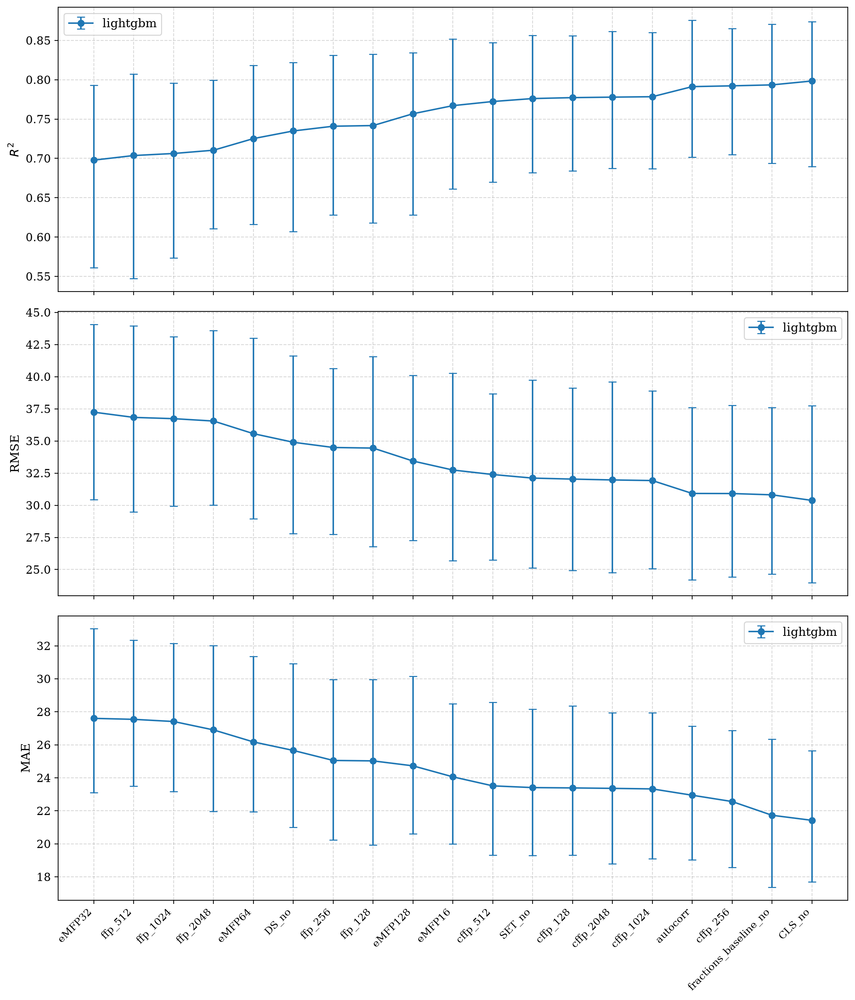

In [20]:
with open("./data/ML/models/results.json") as f:
    res = json.load(f)

datasets = [
    "fractions_baseline_no", "autocorr", "cffp_1024", "cffp_128", "cffp_2048",
    "cffp_256", "cffp_512", "eMFP128", "eMFP16", "eMFP32", "eMFP64",
    "ffp_1024", "ffp_128", "ffp_2048", "ffp_256", "ffp_512", "CLS_no", "SET_no", "DS_no"
]
metrics, titles = ["r2", "rmse", "mae"], ["$R^2$", "RMSE", "MAE"]
models = ["lightgbm"]

fig, axes = plt.subplots(3, 1, figsize=(12, 14), sharex=True)

for i, m_name in enumerate(metrics):
    base_mean = np.array(res[models[0]][m_name]["mean"])
    sort_idx = np.argsort(base_mean) if m_name == "r2" else np.argsort(base_mean)[::-1]

    sorted_ds = [datasets[idx] for idx in sort_idx]
    x = np.arange(len(sorted_ds))

    for m_label in models:
        if m_label not in res:
            continue
        m = np.array(res[m_label][m_name]["mean"])[sort_idx]
        l = np.array(res[m_label][m_name]["ci_low"])[sort_idx]
        h = np.array(res[m_label][m_name]["ci_high"])[sort_idx]

        axes[i].errorbar(x, m, yerr=[m - l, h - m], fmt="o-", capsize=4, elinewidth=1.5, label=m_label)

    axes[i].set_ylabel(titles[i], fontsize=12)
    axes[i].grid(True, linestyle="--", alpha=0.5)
    axes[i].legend(loc="best")

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(sorted_ds, rotation=45, ha="right", fontsize=10)
plt.tight_layout()
plt.show()


ValueError: 'yerr' must not contain negative values

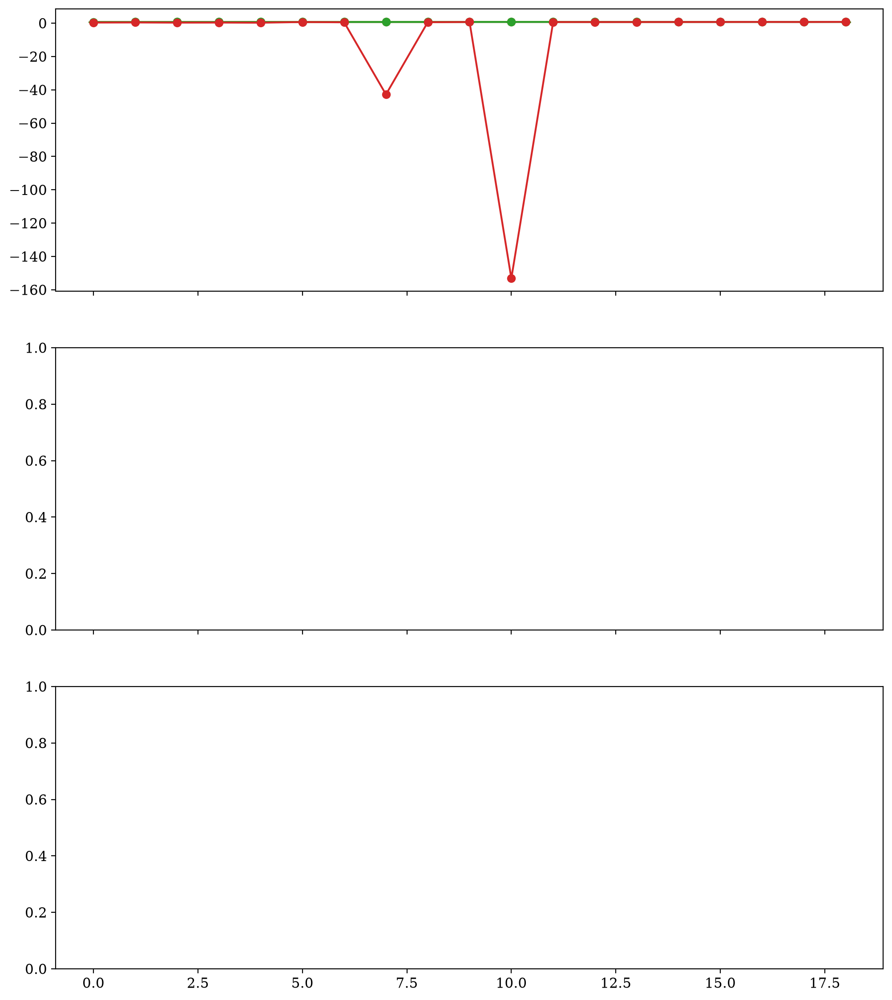

In [21]:
with open("./data/ML/models/results.json") as f:
    res = json.load(f)

datasets = [
    "fractions_baseline_no", "autocorr", "cffp_1024", "cffp_128", "cffp_2048",
    "cffp_256", "cffp_512", "eMFP128", "eMFP16", "eMFP32", "eMFP64",
    "ffp_1024", "ffp_128", "ffp_2048", "ffp_256", "ffp_512", "CLS_no", "SET_no", "DS_no"
]
metrics, titles = ["r2", "rmse", "mae"], ["$R^2$", "RMSE", "MAE"]
models = ["xgboost", "catboost", "lightgbm", "linear", "gp"]

fig, axes = plt.subplots(3, 1, figsize=(12, 14), sharex=True)

for i, m_name in enumerate(metrics):
    base_mean = np.array(res[models[0]][m_name]["mean"])
    sort_idx = np.argsort(base_mean) if m_name == "r2" else np.argsort(base_mean)[::-1]

    sorted_ds = [datasets[idx] for idx in sort_idx]
    x = np.arange(len(sorted_ds))

    for m_label in models:
        if m_label not in res:
            continue
        m = np.array(res[m_label][m_name]["mean"])[sort_idx]
        l = np.array(res[m_label][m_name]["ci_low"])[sort_idx]
        h = np.array(res[m_label][m_name]["ci_high"])[sort_idx]

        axes[i].errorbar(x, m, yerr=[m - l, h - m], fmt="o-", capsize=4, elinewidth=1.5, label=m_label)

    axes[i].set_ylabel(titles[i], fontsize=12)
    axes[i].grid(True, linestyle="--", alpha=0.5)
    axes[i].legend(loc="best")

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(sorted_ds, rotation=45, ha="right", fontsize=10)
plt.tight_layout()
plt.show()


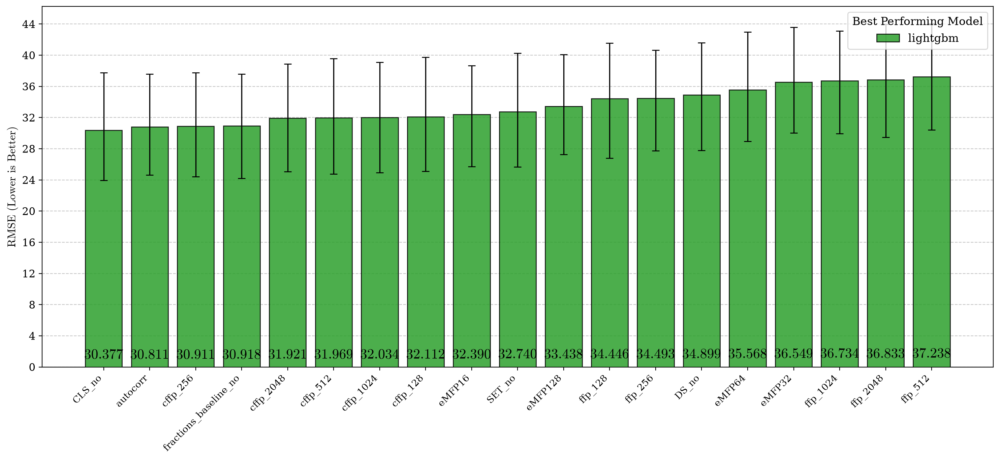

In [22]:
plt.rcParams.update({"text.usetex": False, "mathtext.fontset": "cm"})

with open("./data/ML/models/results.json") as f:
    res = json.load(f)

datasets_names = ["fractions_baseline_no", "autocorr", "cffp_1024", "cffp_128", "cffp_2048", "cffp_256", "cffp_512", "eMFP128", "eMFP16", "eMFP32", "eMFP64", "ffp_1024", "ffp_128", "ffp_2048", "ffp_256", "ffp_512", "CLS_no", "SET_no", "DS_no"]
models_list = ["lightgbm"]
model_colors = {"xgboost": "#1f77b4", "catboost": "#ff7f0e", "lightgbm": "#2ca02c", "linear": "#d62728", "gp": "#d65728"}

best_data = []
for idx, ds_name in enumerate(datasets_names):
    best_m, min_rmse = None, float("inf")
    for model in models_list:
        if model in res and idx < len(res[model]["rmse"]["mean"]):
            mean_val = res[model]["rmse"]["mean"][idx]
            if mean_val < min_rmse:
                min_rmse, best_m = mean_val, model
    if best_m:
        best_data.append({"name": ds_name, "model": best_m, "mean": min_rmse, "low": res[best_m]["rmse"]["ci_low"][idx], "high": res[best_m]["rmse"]["ci_high"][idx]})

best_data.sort(key=lambda item: item["mean"])

names_arr = [item["name"] for item in best_data]
means_arr = np.array([item["mean"] for item in best_data])
colors_arr = [model_colors[item["model"]] for item in best_data]
yerr_low = means_arr - np.array([item["low"] for item in best_data])
yerr_high = np.array([item["high"] for item in best_data]) - means_arr

fig, ax = plt.subplots(figsize=(15, 7))
bars = ax.bar(names_arr, means_arr, color=colors_arr, edgecolor="black", alpha=0.85, zorder=3)
ax.errorbar(names_arr, means_arr, yerr=[yerr_low, yerr_high], fmt="none", ecolor="black", capsize=4, elinewidth=1.2, zorder=4)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h * 0.02, f"${h:.3f}$", 
            ha='center', va='bottom', fontsize=15, color='black', fontweight='bold',
            bbox=dict(facecolor='white', alpha=0, edgecolor='none', pad=0.5))

ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=15))
ax.set_ylabel(r"$\mathrm{RMSE}\ (\mathrm{Lower\ is\ Better})$", fontsize=12)
ax.set_xticks(range(len(names_arr)))
ax.set_xticklabels(names_arr, rotation=45, ha="right", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.7, zorder=0)

labels_added = set()
for bar, item in zip(bars, best_data):
    if item["model"] not in labels_added:
        bar.set_label(item["model"])
        labels_added.add(item["model"])

ax.legend(title="Best Performing Model", loc="upper right")
plt.tight_layout()
plt.show()


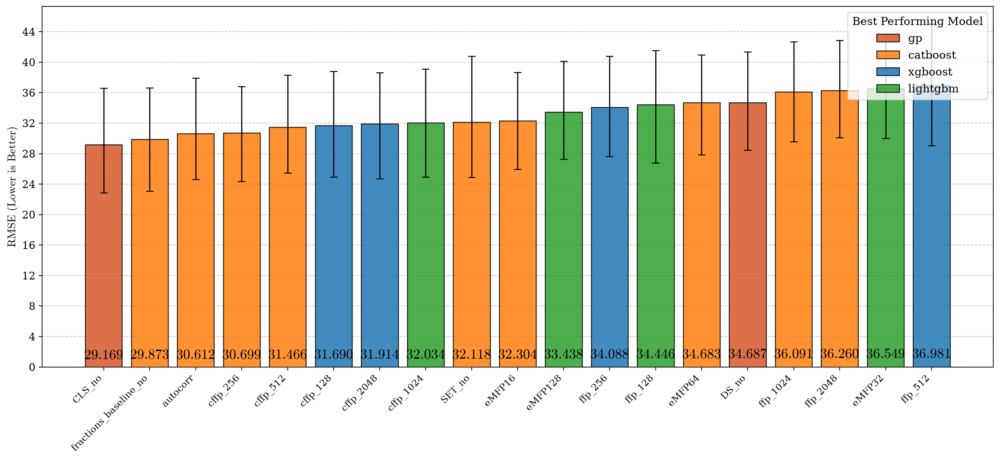

In [23]:
plt.rcParams.update({"text.usetex": False, "mathtext.fontset": "cm"})

with open("./data/ML/models/results.json") as f:
    res = json.load(f)

datasets_names = ["fractions_baseline_no", "autocorr", "cffp_1024", "cffp_128", "cffp_2048", "cffp_256", "cffp_512", "eMFP128", "eMFP16", "eMFP32", "eMFP64", "ffp_1024", "ffp_128", "ffp_2048", "ffp_256", "ffp_512", "CLS_no", "SET_no", "DS_no"]
models_list = ["xgboost", "catboost", "lightgbm", "linear", "gp"]
model_colors = {"xgboost": "#1f77b4", "catboost": "#ff7f0e", "lightgbm": "#2ca02c", "linear": "#d62728", "gp": "#d65728"}

best_data = []
for idx, ds_name in enumerate(datasets_names):
    best_m, min_rmse = None, float("inf")
    for model in models_list:
        if model in res and idx < len(res[model]["rmse"]["mean"]):
            mean_val = res[model]["rmse"]["mean"][idx]
            if mean_val < min_rmse:
                min_rmse, best_m = mean_val, model
    if best_m:
        best_data.append({"name": ds_name, "model": best_m, "mean": min_rmse, "low": res[best_m]["rmse"]["ci_low"][idx], "high": res[best_m]["rmse"]["ci_high"][idx]})

best_data.sort(key=lambda item: item["mean"])

names_arr = [item["name"] for item in best_data]
means_arr = np.array([item["mean"] for item in best_data])
colors_arr = [model_colors[item["model"]] for item in best_data]
yerr_low = means_arr - np.array([item["low"] for item in best_data])
yerr_high = np.array([item["high"] for item in best_data]) - means_arr

fig, ax = plt.subplots(figsize=(15, 7))
bars = ax.bar(names_arr, means_arr, color=colors_arr, edgecolor="black", alpha=0.85, zorder=3)
ax.errorbar(names_arr, means_arr, yerr=[yerr_low, yerr_high], fmt="none", ecolor="black", capsize=4, elinewidth=1.2, zorder=4)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h * 0.02, f"${h:.3f}$", 
            ha='center', va='bottom', fontsize=15, color='black', fontweight='bold',
            bbox=dict(facecolor='white', alpha=0, edgecolor='none', pad=0.5))

ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=15))
ax.set_ylabel(r"$\mathrm{RMSE}\ (\mathrm{Lower\ is\ Better})$", fontsize=12)
ax.set_xticks(range(len(names_arr)))
ax.set_xticklabels(names_arr, rotation=45, ha="right", fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.7, zorder=0)

labels_added = set()
for bar, item in zip(bars, best_data):
    if item["model"] not in labels_added:
        bar.set_label(item["model"])
        labels_added.add(item["model"])

ax.legend(title="Best Performing Model", loc="upper right")
plt.tight_layout()
plt.show()


## Figures

#### prep

In [64]:
import numpy as np
import h5py
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors, rdPartialCharges, rdmolops

CACHE = Path("data/chains.npz")

if not CACHE.exists():
    mon = {'HEA':'C=CC(=O)OCCO','BA':'C=CC(=O)OCCCC','CBEA':'C=CC(=O)OCCC(=O)O',
           'ATAC':'C=CC(=O)OCC[N+](C)(C)C','PEA':'C=CC(=O)OCCOc1ccccc1','AAm':'C=CC(=O)N'}

    def ac2d(mol, L=8):
        if mol is None or mol.GetNumAtoms() < 2:
            return np.zeros(3 * L, np.float32)
        m = Chem.Mol(mol); rdPartialCharges.ComputeGasteigerCharges(m)
        dm = rdmolops.GetDistanceMatrix(m); A = list(m.GetAtoms())
        arrs = [np.array([c[0] for c in rdMolDescriptors._CalcCrippenContribs(m)], np.float32),
                np.array([float(a.GetProp('_GasteigerCharge')) if a.HasProp('_GasteigerCharge') else 0. for a in A], np.float32),
                np.array([a.GetIsAromatic() or a.GetHybridization() == Chem.HybridizationType.SP2 for a in A], np.float32)]
        out = []
        for p in arrs:
            for l in range(1, L + 1):
                i, j = np.where(np.triu(dm == l, 1))
                out.append(0. if not len(i) else float((p[i] * p[j]).sum() / len(i)))
        return np.array(out, np.float32)

    feats = np.array([np.concatenate([ac2d(Chem.MolFromSmiles(s)),
                                       rdMolDescriptors.CalcAUTOCORR2D(Chem.MolFromSmiles(s))])
                      for s in mon.values()], np.float32)

    with h5py.File('data/poly_datasets.h5', 'r') as f:
        D = f['autocorr'][:]

    n, L_chain = D.shape[0], D.shape[1]
    chains = np.full((n, L_chain), -1, np.int8)
    comp = np.zeros((n, 6), np.float32)
    n_unmatched = 0
    for i in range(n):
        for j in range(L_chain):
            k = next((k for k in range(6)
                      if np.allclose(D[i, j], feats[k], rtol=1e-5, atol=1e-8)), -1)
            if k >= 0:
                chains[i, j] = k
                comp[i, k] += 1
            else:
                n_unmatched += 1
    comp /= L_chain
    np.savez_compressed(CACHE, chains=chains, comp=comp)
    print(f"chains: {chains.shape} | unmatched: {n_unmatched} "
          f"({100*n_unmatched/chains.size:.3f}%)")
else:
    d = np.load(CACHE)
    chains, comp = d['chains'], d['comp']
    print(f"loaded cache: chains {chains.shape}")

chains: (347, 1000) | unmatched: 0 (0.000%)


### Figures

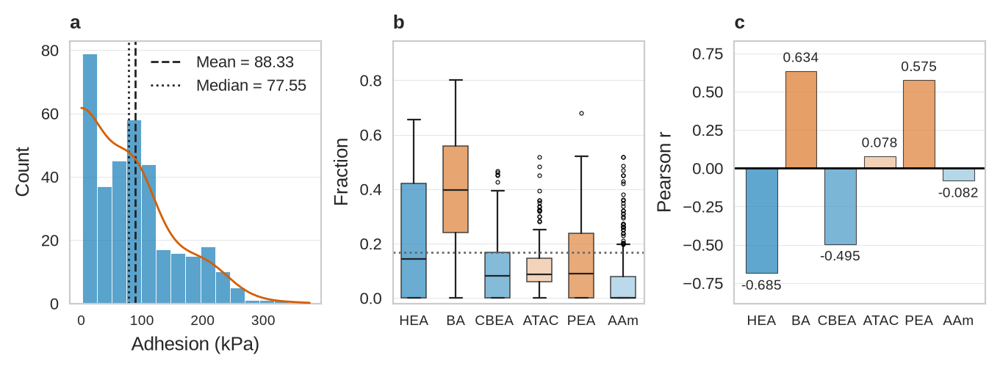

In [109]:
FIG = Path("figs"); FIG.mkdir(exist_ok=True)

mon = {'HEA':'C=CC(=O)OCCO', 'BA':'C=CC(=O)OCCCC', 'CBEA  ':'C=CC(=O)OCCC(=O)O',
       ' ATAC':'C=CC(=O)OCC[N+](C)(C)C', 'PEA':'C=CC(=O)OCCOc1ccccc1', 'AAm':'C=CC(=O)N'}
names = list(mon)

corr = np.array([pearsonr(comp[:, k], adhesion)[0] for k in range(6)])
pos_rgb, neg_rgb = np.array([0.835, 0.369, 0.000]), np.array([0.000, 0.447, 0.698])
sat = lambda c: 0.3 + 0.7 * min(abs(c), 1)
col = lambda c: tuple((1 - sat(c)) * np.ones(3) + sat(c) * (pos_rgb if c >= 0 else neg_rgb))
colors = [col(c) for c in corr]
nz = adhesion[adhesion > 0]

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 9.5,
    "axes.labelsize": 9.5,
    "axes.titlesize": 9.5,
    "xtick.labelsize": 7,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
})

fig, ax = plt.subplots(1, 3, figsize=(6.69, 2.4), constrained_layout=True)

for a in ax:
    a.grid(False)
    a.grid(axis='y', color="#CCCCCC", lw=0.3, alpha=0.6)
    a.set_axisbelow(True)

sns.histplot(nz, kde=False, ax=ax[0],
             color="#0072B2", edgecolor="white", alpha=0.65, linewidth=0.3)

kde_func = stats.gaussian_kde(np.concatenate([-nz, nz]))
x_kde = np.linspace(0, nz.max() * 1.1, 500)
y_kde = kde_func(x_kde) * 2
bin_width = ax[0].patches[0].get_width() if len(ax[0].patches) > 0 else 1
ax[0].plot(x_kde, y_kde * len(nz) * bin_width, color="#D55E00", lw=1.0, zorder=3)

ax[0].axvline(np.mean(nz), color="#222222", ls="--", lw=1.0, label=f"Mean = {np.mean(nz):.2f}")
ax[0].axvline(np.median(nz), color="#222222", ls=":", lw=1.0, label=f"Median = {np.median(nz):.2f}")
ax[0].set(xlabel="Adhesion (kPa)", ylabel="Count")
ax[0].set_title("a", loc="left", fontweight="bold")
ax[0].legend(frameon=False, loc="upper right")

flierprops = dict(marker='o', markerfacecolor='none', markeredgecolor='black',
                  markersize=1.8, markeredgewidth=0.4)
bp = ax[1].boxplot([comp[:, k] for k in range(6)], patch_artist=True, widths=0.6,
                   flierprops=flierprops)
for p, c in zip(bp['boxes'], colors):
    p.set(facecolor=c, edgecolor="#222222", linewidth=0.6, alpha=0.75)
for key, part in bp.items():
    if key not in ('boxes', 'fliers'):
        for it in part:
            it.set(color="#222222", lw=0.8)
ax[1].set_xticks(range(1, 7))
ax[1].set_xticklabels(names)
ax[1].set(ylabel="Fraction", ylim=(-0.02, max(comp.max(), 0.9) * 1.05))
ax[1].set_title("b", loc="left", fontweight="bold")
ax[1].axhline(1/6, color="#666666", ls=":", lw=1.0)

b3 = ax[2].bar(range(6), corr, color=colors, edgecolor="#222222",
               linewidth=0.4, alpha=0.80)
ax[2].set_xticks(range(6))
ax[2].set_xticklabels(names)
ax[2].set(ylabel="Pearson r")
ax[2].set_title("c", loc="left", fontweight="bold")
ax[2].axhline(0, color="black", lw=1.0)
lo, hi = min(corr.min(), 0), max(corr.max(), 0)
pad = max(hi - lo, 0.02) * 0.15
ax[2].set_ylim(lo - pad, hi + pad)
for b, v in zip(b3, corr):
    ax[2].annotate(f'{v:.3f}', (b.get_x() + b.get_width()/2, v),
                   textcoords="offset points", xytext=(0, 3 if v >= 0 else -3),
                   ha='center', va='bottom' if v >= 0 else 'top', fontsize=7)

plt.savefig(FIG / "figure_adhesion.pdf")
plt.savefig(FIG / "figure_1.png", dpi=600)

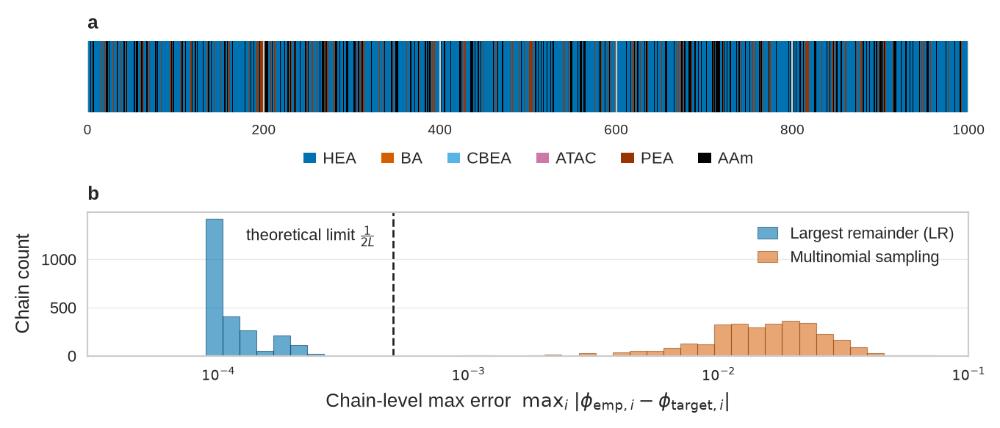

In [107]:
FIG = Path("figs"); FIG.mkdir(exist_ok=True)

MON_COLORS = ["#0072B2", "#D55E00", "#56B4E9", "#CC79A7", "#993300", "#000000"]
names = ["HEA", "BA", "CBEA", "ATAC", "PEA", "AAm"]
K = len(names)

d = np.load("data/chains.npz")
chains, comp = d["chains"], d["comp"]
L = chains.shape[1]

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 9.5,
    "axes.labelsize": 9.5,
    "axes.titlesize": 9.5,
    "xtick.labelsize": 7,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
})

rng = np.random.default_rng(42)
n_trials = 3000
phi_true = comp[rng.integers(0, len(comp), n_trials)].copy()
phi_true = np.clip(phi_true, 1e-4, None)
phi_true /= phi_true.sum(axis=1, keepdims=True)

def lr_assign_batch(phi_matrix, L):
    N = phi_matrix * L
    counts = np.floor(N).astype(int)
    shortfall = L - counts.sum(axis=1)
    order = np.argsort(-(N - counts), axis=1)
    for i, s in enumerate(shortfall):
        if s > 0:
            counts[i, order[i, :s]] += 1
    return counts

lr_phi = lr_assign_batch(phi_true, L) / L
mn_phi = np.array([rng.multinomial(L, r) for r in phi_true]) / L

lr_err = np.max(np.abs(lr_phi - phi_true), axis=1)
mn_err = np.max(np.abs(mn_phi - phi_true), axis=1)
fig, axes = plt.subplots(2, 1, figsize=(6.69, 2.8),
                          gridspec_kw={"height_ratios": [0.6, 1.2]},
                          constrained_layout=True)
cmap = ListedColormap(MON_COLORS)

seq = chains[201]
axes[0].imshow(seq.reshape(1, -1), aspect="auto", cmap=cmap,
               extent=[0, L, 0, 1], interpolation="nearest")

axes[0].set(xlim=(0, L), ylim=(0, 1), yticks=[])
axes[0].set_title("a", loc="left", fontweight="bold")
for s in axes[0].spines.values():
    s.set_visible(False)
axes[0].tick_params(left=False)
handles = [Patch(facecolor=MON_COLORS[k], edgecolor="none", label=names[k]) for k in range(K)]
axes[0].legend(handles=handles, loc="upper center", ncol=6, frameon=False,
               bbox_to_anchor=(0.5, -0.45), handlelength=0.8, handleheight=0.6,
               handletextpad=0.4, columnspacing=1.5, borderaxespad=0.0)

bins = np.logspace(-5, -1, 60)
axes[1].hist(lr_err, bins=bins,
             color="#0072B2", alpha=0.60, edgecolor="#003B60", linewidth=0.4,
             label="Largest remainder (LR)")
axes[1].hist(mn_err, bins=bins,
             color="#D55E00", alpha=0.55, edgecolor="#8A3D00", linewidth=0.4,
             label="Multinomial sampling")
axes[1].axvline(1 / (2 * L), color="#222222", ls="--", lw=1.0)
axes[1].set_xscale("log")

axes[1].set_xlim(3e-5, 1e-1)
axes[1].set_xticks([1e-4, 1e-3, 1e-2, 1e-1])
axes[1].set_xticklabels([r"$10^{-4}$", r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$"])

axes[1].set(xlabel=r"Chain-level max error  $\mathrm{max}_{i}\;|\phi_{\mathrm{emp},i} - \phi_{\mathrm{target},i}|$",
            ylabel="Chain count")

axes[1].set_title("b", loc="left", fontweight="bold")
axes[1].legend(frameon=False, loc="upper right", handlelength=1.2)
axes[1].grid(False)
axes[1].grid(axis="y", color="#EAEAEA", lw=0.5)
axes[1].set_axisbelow(True)

ymax = axes[1].get_ylim()[1]
axes[1].text(1 / (2 * L) * 0.85, ymax * 0.9, r"theoretical limit $\frac{1}{2L}$",
             ha="right", va="top", fontsize=8, color="#222222")

plt.savefig(FIG / "figure_chain.pdf")
plt.savefig(FIG / "figure_2.png", dpi=600)

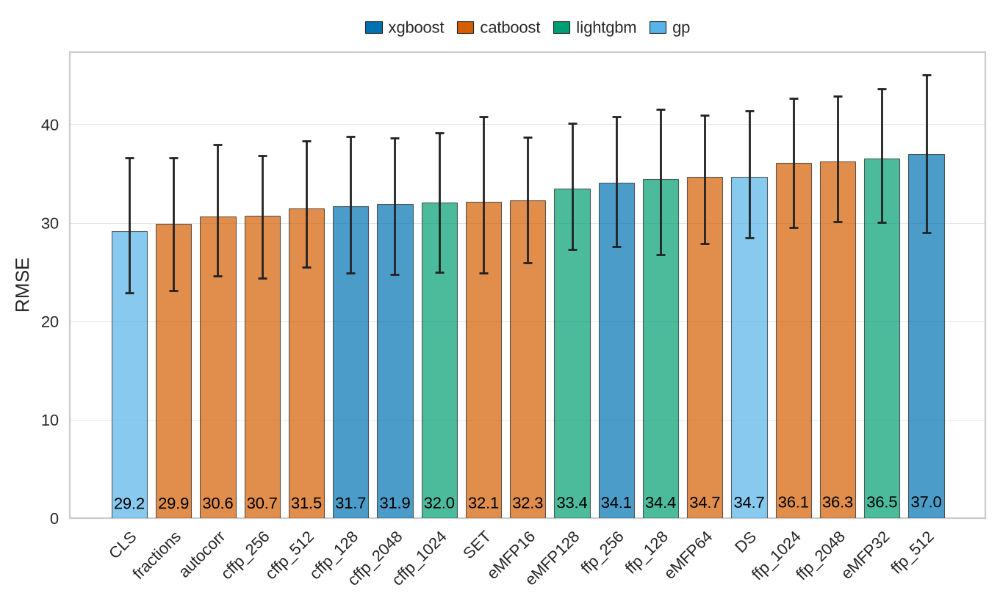

In [108]:
FIG = Path("figs"); FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 9.5,
    "axes.labelsize": 9.5,
    "axes.titlesize": 9.5,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
})


with open("./data/ML/models/results.json") as f:
    res = json.load(f)

datasets_names = ["fractions", "autocorr", "cffp_1024", "cffp_128", "cffp_2048",
                  "cffp_256", "cffp_512", "eMFP128", "eMFP16", "eMFP32", "eMFP64",
                  "ffp_1024", "ffp_128", "ffp_2048", "ffp_256", "ffp_512",
                  "CLS", "SET", "DS"]
models_list = ["xgboost", "catboost", "lightgbm", "linear", "gp"]
model_colors = {
    "xgboost":  "#0072B2",
    "catboost": "#D55E00",
    "lightgbm": "#009E73",
    "linear":   "#CC79A7",
    "gp":       "#56B4E9",
}

best_data = []
for idx, ds_name in enumerate(datasets_names):
    best_m, min_rmse = None, float("inf")
    for model in models_list:
        if model in res and idx < len(res[model]["rmse"]["mean"]):
            m = res[model]["rmse"]["mean"][idx]
            if m < min_rmse:
                min_rmse, best_m = m, model
    if best_m:
        best_data.append({"name": ds_name, "model": best_m, "mean": min_rmse,
                          "low": res[best_m]["rmse"]["ci_low"][idx],
                          "high": res[best_m]["rmse"]["ci_high"][idx]})
best_data.sort(key=lambda d: d["mean"])

names_arr = [d["name"] for d in best_data]
means_arr = np.array([d["mean"] for d in best_data])
colors_arr = [model_colors[d["model"]] for d in best_data]
yerr_low = means_arr - np.array([d["low"] for d in best_data])
yerr_high = np.array([d["high"] for d in best_data]) - means_arr

fig, ax = plt.subplots(figsize=(6.69, 4.0), constrained_layout=True)
ax.grid(False)
ax.grid(axis="y", color="#CCCCCC", lw=0.3, alpha=0.6)
ax.set_axisbelow(True)

bars = ax.bar(range(len(names_arr)), means_arr, color=colors_arr,
              edgecolor="#222222", linewidth=0.4, alpha=0.70, zorder=3)
ax.errorbar(range(len(names_arr)), means_arr, yerr=[yerr_low, yerr_high],
            fmt="none", ecolor="#222222", capsize=2.0,
            elinewidth=1.0, capthick=1.0, zorder=4)

for bar, h in zip(bars, means_arr):
    ax.text(bar.get_x() + bar.get_width()/2, h * 0.02, f"{h:.1f}",
            ha="center", va="bottom", fontsize=8, color="black", zorder=5)

ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.set_ylabel("RMSE")
ax.set_xticks(range(len(names_arr)))
ax.set_xticklabels(names_arr, rotation=45, ha="right", rotation_mode="anchor")

winners = {d["model"] for d in best_data}
handles = [Patch(facecolor=model_colors[m], edgecolor="#222222", linewidth=0.4, label=m)
           for m in models_list if m in winners]
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02),
          ncol=len(handles), frameon=False, borderaxespad=0,
          handlelength=1.0, handletextpad=0.4, columnspacing=0.8)

plt.savefig(FIG / "figure_rmse.pdf")
plt.savefig(FIG / "figure_3.png", dpi=600)

###### 